# Learning the $\omega$-limit partition: Duffing oscillator

This notebook walks through every stage of Algorithm 1 from *Learning Omega-Limit Partitions from
Approximate Koopman Invariants* on the `duffing` example, using the `src_omega_partition` library
directly (the same code the `scripts/` pipeline runs). At each stage we sweep the relevant parameter
to show what it does, then fix it at the value used in the paper
(`configs/duffing/build_partition.json`).

The unforced, damped Duffing oscillator $\ddot x = x - x^3 - \delta \dot x$ has two stable equilibria at $(\pm 1, 0)$ separated by the stable manifold of the saddle at the origin. Its $\omega$-limit partition therefore has **two** cells (the two basins of attraction), and we expect $m = 2$ approximate invariant observables: the constant function and one non-trivial observable that takes a different value on each basin.

**Pipeline**

1. Dictionary $\Phi$ (Gaussian RBFs + polynomials) and the generalized eigenvalue problem
   $M w = \lambda N w$ that yields approximate invariant observables $f_j = \Phi w_j$ — parameters
   $\gamma$ (RBF precision), $\epsilon$ (eigenvalue tolerance).
2. Per-coordinate 1-D $k$-means on each $f_j$; the product of the scalar labels defines the *fine
   cells* — parameters $k_1, \ldots, k_r$.
3. Occupancy filter — parameter $\tau_{\mathrm{occ}}$.
4. Transition-based merging of fine cells — parameter $\tau_{\mathrm{tr}}$.
5. Value-based merging of the transition-merged nodes — parameter $\tau_{\mathrm{val}}$.
6. Optional robustness margin that drops points too close to a boundary — parameter
   $\tau_{\mathrm{robust}}$ (not in the paper).
7. Validation against labeled trajectories via class anchors.
8. Switched local EDMD models on the final partition vs a vanilla EDMD model with the same
   dictionary (lift-once rollouts on the configured initial conditions).
9. Sweep of the EDMD dictionary (RBF centers, $\gamma$, polynomial degree) with the partition fixed.

> **Remark (Parameter Tuning, from the paper).** We increase $\gamma$ until the generalized
> eigenvalue problem produces enough approximate invariant observables with eigenvalues below the
> prescribed tolerance $\epsilon$. We then choose the scalar clustering integers $k_1, \ldots, k_r$.
> In practice, the parity of $k_j$ can affect the quality of the initial fine partition. For the
> merging thresholds, we tune the transition threshold $\tau_{\mathrm{tr}}$ before using value-based
> merging. Specifically, we first set $\tau_{\mathrm{val}} = 0$ so that merging is driven only by
> observed transitions between fine cells. We then vary $\tau_{\mathrm{tr}}$. Smaller values of
> $\tau_{\mathrm{tr}}$ produce more aggressive merging and, in the extreme, may collapse the
> partition to a single cell. Starting from a small value, we gradually increase $\tau_{\mathrm{tr}}$
> until persistent cells appear and the resulting partition is approximately stationary on the data.
> After $\tau_{\mathrm{tr}}$ is fixed, the value-based threshold $\tau_{\mathrm{val}}$ can be used as
> a secondary refinement parameter. In our experiments, transition-based merging was often
> sufficient, and $\tau_{\mathrm{val}}$ was needed only for fine-tuning.

> Run this notebook in the `macbook_env` conda environment from the `notebooks/` folder
> (`jupyter lab notebooks/`). It only reads the committed datasets and writes nothing to `data/`.

## 0. Setup

In [1]:
import json
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src_omega_partition").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

from src_omega_partition.paths import resolve
from src_omega_partition.dictionary import build_rbf_polynomial_dictionary
from src_omega_partition.invariants import (
    compute_approximate_invariant_observables,
    evaluate_invariant_embedding,
    select_invariant_modes,
)
from src_omega_partition.partition import (
    build_partition_inference,
    compute_relative_boundary_distances,
    fit_graph_merged_partition,
)
from src_omega_partition.anchors import (
    build_anchor_points,
    classify_embedding_with_anchors,
    print_anchor_assignments,
    print_classification_table,
)
from src_omega_partition.plotting import (
    plot_boundary_distance_histogram,
    plot_cell_weights,
    plot_inter_centroid_distances,
    plot_invariant_embedding_2d,
    plot_invariant_scalar_histograms,
    plot_misclassified_points,
    plot_state_partition_2d,
)

SYSTEM = "duffing"
build_cfg = json.load(open(PROJECT_ROOT / f"configs/{SYSTEM}/build_partition.json"))
validate_cfg = json.load(open(PROJECT_ROOT / f"configs/{SYSTEM}/validate_partition.json"))

PAPER = {k: build_cfg[k] for k in (
    "gamma", "d_poly", "epsilon", "reg", "max_invariant_modes", "skip_first_mode",
    "scalar_cluster_count", "tau_occ", "tau_tr", "tau_val", "tau_robust", "random_state")}
pd.Series({k: str(v) for k, v in PAPER.items()}, name="paper value").to_frame()

,paper value
gamma,30.0
d_poly,0
epsilon,0.0001
reg,1e-08
max_invariant_modes,2
skip_first_mode,False
scalar_cluster_count,"[2, 4]"
tau_occ,0.002
tau_tr,0.005
tau_val,0.0


### Data

Training snapshot pairs $(x_i, y_i)$ with $y_i = T(x_i)$ one sampling step later, the $k$-means RBF
centers computed by `generate_data.py`, and the labeled validation trajectories from
`generate_validation_data.py` (label = which attractor the trajectory eventually reached).

training snapshots: 50000, RBF centers: 500, validation snapshots: 399200, classes: 2


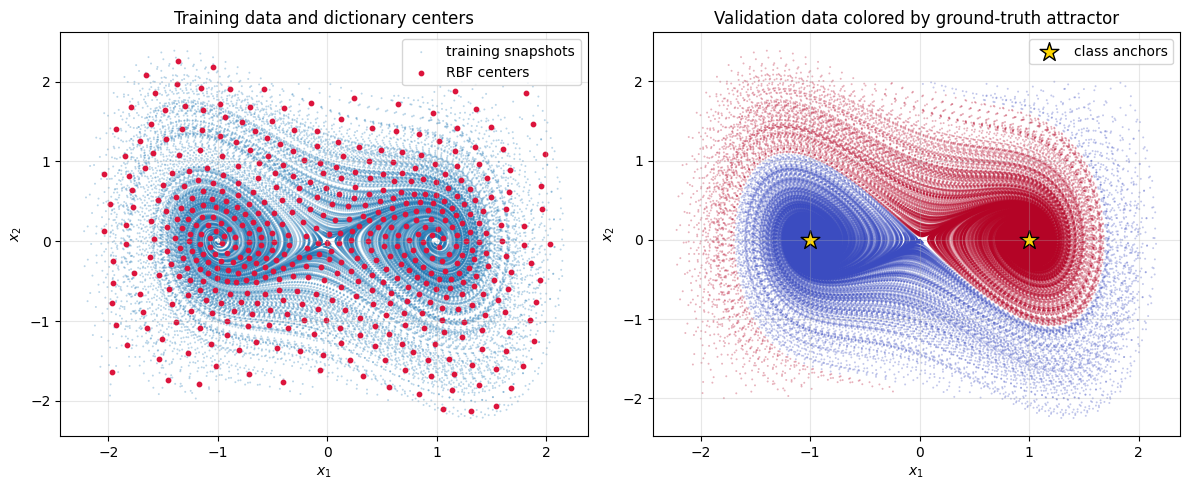

In [2]:
data = np.load(resolve(build_cfg["data_path"]))
X, Y, centers_global = data["X"], data["Y"], data["centers_global"]
n = X.shape[1]

val = np.load(resolve(validate_cfg["validation_data_path"]))
X_val, labels_val = val["X"], val["labels"].astype(np.int64)

anchors = build_anchor_points(
    {"target_equilibria": validate_cfg.get("target_equilibria"),
     "target_data_paths": validate_cfg.get("target_data_paths")},
    state_dim=n,
)
print(f"training snapshots: {X.shape[0]}, RBF centers: {centers_global.shape[0]}, "
      f"validation snapshots: {X_val.shape[0]}, classes: {anchors.shape[0]}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(X[:, 0], X[:, 1], s=2, alpha=0.3, edgecolors="none", label="training snapshots")
axes[0].scatter(centers_global[:, 0], centers_global[:, 1], s=10, c="crimson", label="RBF centers")
axes[0].set_title("Training data and dictionary centers")
axes[1].scatter(X_val[:, 0], X_val[:, 1], s=2, c=labels_val, cmap="coolwarm", alpha=0.3, edgecolors="none")
axes[1].scatter(anchors[:, 0], anchors[:, 1], s=200, marker="*", c="gold", edgecolors="black", label="class anchors")
axes[1].set_title("Validation data colored by ground-truth attractor")
for ax in axes:
    ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.grid(alpha=0.3); ax.legend(loc="upper right")
plt.tight_layout(); plt.show()

### Helpers

Three thin wrappers around the library so every experiment below is a one-liner:

- `compute_embedding(gamma, ...)` builds the dictionary, solves the GEP and evaluates the invariant
  embedding on the training pairs, the validation states and the anchors (steps 1 of the pipeline).
- `fit_partition(emb, ...)` runs steps 2–6 (`fit_graph_merged_partition`) and returns both the raw
  result and the inference dict that `validate_partition.py` would load from `partition_output.npz`.
- `validate(emb, inference)` maps partition ids to classes through the anchors and scores the
  validation set (step 7). It returns `None` when validation is impossible because both anchors fall
  in the same cell or an anchor was dropped — that is what a collapsed partition looks like.

In [3]:
def compute_embedding(gamma, *, d_poly=PAPER["d_poly"], epsilon=PAPER["epsilon"], reg=PAPER["reg"],
                      max_modes=PAPER["max_invariant_modes"], skip_first_mode=PAPER["skip_first_mode"]):
    Phi = build_rbf_polynomial_dictionary(n, centers_global, gamma, d_poly)
    Phi_X, Phi_Y = Phi.evaluate(X), Phi.evaluate(Y)
    lam, vecs = compute_approximate_invariant_observables(Phi_X, Phi_Y, epsilon=epsilon, reg=reg)
    eigvals, coeffs = select_invariant_modes(lam, vecs, epsilon=epsilon, max_modes=max_modes,
                                             skip_first_mode=skip_first_mode)
    return dict(
        gamma=gamma, d_poly=d_poly, eigvals=eigvals, coeffs=coeffs,
        F_X=evaluate_invariant_embedding(Phi_X, coeffs),
        F_Y=evaluate_invariant_embedding(Phi_Y, coeffs),
        F_val=evaluate_invariant_embedding(Phi.evaluate(X_val), coeffs),
        F_anchors=evaluate_invariant_embedding(Phi.evaluate(anchors), coeffs),
    )


def fit_partition(emb, **overrides):
    params = dict(n_clusters=PAPER["scalar_cluster_count"], tau_occ=PAPER["tau_occ"], tau_tr=PAPER["tau_tr"],
                  tau_val=PAPER["tau_val"], tau_robust=0.0, random_state=PAPER["random_state"])
    params.update(overrides)
    result = fit_graph_merged_partition(emb["F_X"], emb["F_Y"], **params)
    inference = build_partition_inference(result, coeffs_inv=emb["coeffs"], centers_global=centers_global,
                                          gamma=emb["gamma"], d_poly=emb["d_poly"], n=n)
    return result, inference


def validate(emb, inference):
    try:
        return classify_embedding_with_anchors(F=emb["F_val"], F_anchors=emb["F_anchors"], anchors=anchors,
                                               gt_labels=labels_val, partition=inference)
    except ValueError as err:   # both anchors in one cell, or an anchor dropped
        return None


def summarize(result, res=None):
    row = dict(
        occupied=result["n_occupied_fine_cells"],
        retained=len(result["retained_cell_ids"]),
        after_tau_tr=len(result["transition_components"]),
        final=len(result["components"]),
        train_dropped=float(np.mean(result["final_labels_X"] < 0)),
    )
    if res is None:
        row.update(val_accuracy=np.nan, val_dropped=np.nan)
    else:
        row.update(val_accuracy=res.table_rows[1].rate, val_dropped=res.table_rows[2].rate)
    return row


def sweep(emb, name, values, **fixed):
    """Fit + validate for each value of one parameter; returns a DataFrame indexed by that parameter."""
    rows = []
    for v in values:
        result, inference = fit_partition(emb, **{name: v}, **fixed)
        rows.append(summarize(result, validate(emb, inference)))
    return pd.DataFrame(rows, index=pd.Index(values, name=name))


def scatter_cells(ax, labels, title, *, X_plot=None, s=3):
    """State-space scatter colored by cell label; dropped points (-1) in gray."""
    X_plot = X if X_plot is None else X_plot
    labels = np.asarray(labels)
    dropped = labels < 0
    ax.scatter(X_plot[dropped, 0], X_plot[dropped, 1], s=s, c="lightgray", edgecolors="none")
    ax.scatter(X_plot[~dropped, 0], X_plot[~dropped, 1], s=s, c=labels[~dropped], cmap="tab20",
               vmin=0, vmax=19, alpha=0.6, edgecolors="none")
    ax.set_title(title); ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.grid(alpha=0.3)


pd.set_option("display.precision", 5)

## 1. Dictionary and approximate invariant observables ($\gamma$, $\epsilon$)

The dictionary is $\Phi(x) = [\exp(-\gamma\|x - c_i\|^2)]_i$ over the $k$-means centers, plus
monomials up to degree `d_poly` (the constant is included whenever `d_poly >= 0`). The generalized
eigenvalue problem
$$ (\Phi_Y - \Phi_X)^\top(\Phi_Y - \Phi_X)\, w = \lambda\, \Phi_Y^\top \Phi_Y\, w $$
measures how much $f = \Phi w$ changes along one step of the data; $\lambda \approx 0$ means
$f$ is approximately invariant. We keep the modes with $\lambda < \epsilon$ (at most
`max_invariant_modes` of them).

**How many is "enough"?** An observable that is invariant under the dynamics must be constant on
each $\omega$-limit component's basin, so with $m$ attractors the space of invariant observables has
dimension $m$. We therefore want *about* $m$ eigenvalues below $\epsilon$ — here $m = 2$
(the constant function plus 1 non-trivial mode) — with a visible gap above
them. Sweeping $\gamma$ shows the two failure modes on either side.

,n(lambda < epsilon),lambda_1,lambda_2,lambda_3,lambda_4
gamma,,,,,
1.000000,391,-1.23e-08,-1.17e-08,-1.14e-08,-1.13e-08
3.000000,252,-1.33e-08,-1.19e-08,-1.18e-08,-1.16e-08
10.000000,38,3.32e-16,5.17e-08,7.8e-08,1.44e-07
30.000000,2,-5.5e-17,7.39e-05,0.000196,0.000225
100.000000,1,3.02e-16,0.000185,0.000288,0.000461


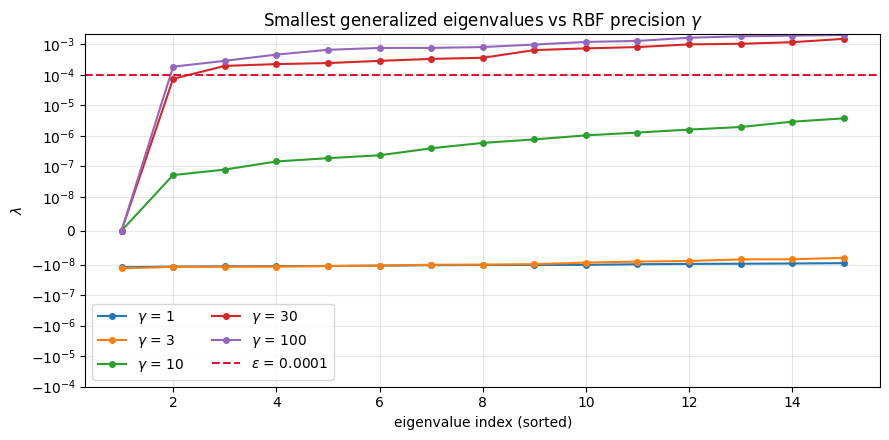

In [4]:
gamma_grid = [1.0, 3.0, 10.0, 30.0, 100.0]
epsilon = PAPER["epsilon"]

spectra = {}
for gamma in gamma_grid:
    Phi = build_rbf_polynomial_dictionary(n, centers_global, gamma, PAPER["d_poly"])
    lam, _ = compute_approximate_invariant_observables(Phi.evaluate(X), Phi.evaluate(Y), epsilon=np.inf, reg=PAPER["reg"])
    spectra[gamma] = np.sort(lam)

summary = pd.DataFrame({
    "n(lambda < epsilon)": [int(np.sum(spectra[g] < epsilon)) for g in gamma_grid],
    "lambda_1": [spectra[g][0] for g in gamma_grid],
    "lambda_2": [spectra[g][1] for g in gamma_grid],
    "lambda_3": [spectra[g][2] for g in gamma_grid],
    "lambda_4": [spectra[g][3] for g in gamma_grid],
}, index=pd.Index(gamma_grid, name="gamma"))
display(summary.style.format({c: "{:.3g}" for c in summary.columns if c.startswith("lambda")}))

fig, ax = plt.subplots(figsize=(9, 4.5))
n_show = 15
for gamma in gamma_grid:
    ax.plot(np.arange(1, n_show + 1), spectra[gamma][:n_show], "o-", ms=4, label=rf"$\gamma$ = {gamma:g}")
ax.axhline(epsilon, color="crimson", ls="--", label=rf"$\epsilon$ = {epsilon:g}")
ax.set_yscale("symlog", linthresh=1e-8)
ax.set_xlabel("eigenvalue index (sorted)"); ax.set_ylabel(r"$\lambda$")
ax.set_title("Smallest generalized eigenvalues vs RBF precision $\\gamma$")
ax.grid(alpha=0.3); ax.legend(ncol=2)
plt.tight_layout(); plt.show()

Two regimes are visible:

- **$\gamma$ too small** (wide bumps): hundreds of eigenvalues sit below $\epsilon$, many of them
  slightly *negative*. Wide RBFs are nearly linearly dependent, so $\Phi_Y^\top\Phi_Y$ is close to
  singular and the GEP returns a large numerical null space, not genuine invariants. Any
  eigenvector from this pile is noise.
- **$\gamma$ too large** (narrow bumps): each RBF sees only a few snapshots, the observables can no
  longer be nearly constant along trajectories, and only the exact constant survives below
  $\epsilon$.

The paper value $\gamma = 30$
is the smallest value on the grid where exactly $m = 2$ eigenvalues fall below
$\epsilon$ with a clear gap to the third. That is the "increase $\gamma$ until enough" rule of the
remark, with "enough" read as "as many as there are attractors, and no spurious extras".

gamma = 30.0: r = 2 invariant modes, eigenvalues [-5.49834349e-17  7.39220427e-05]  (28.0s)


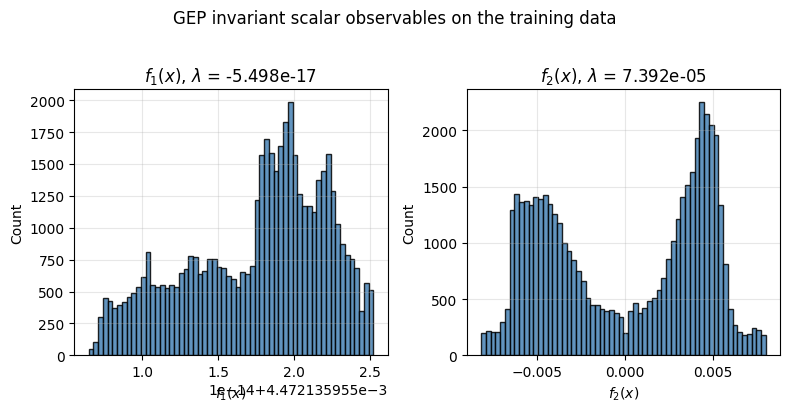

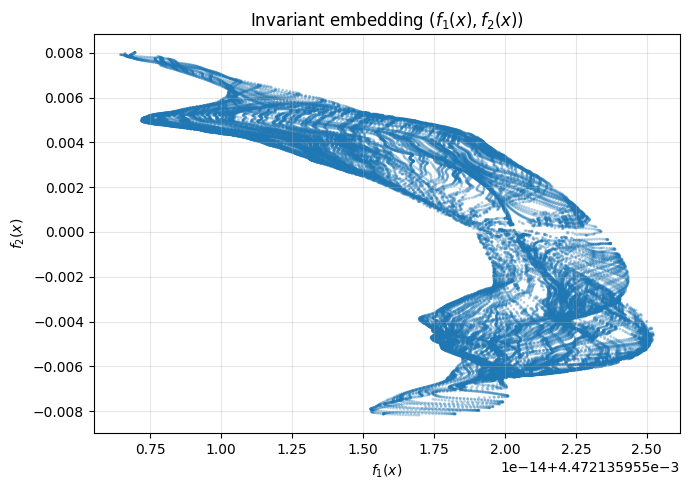

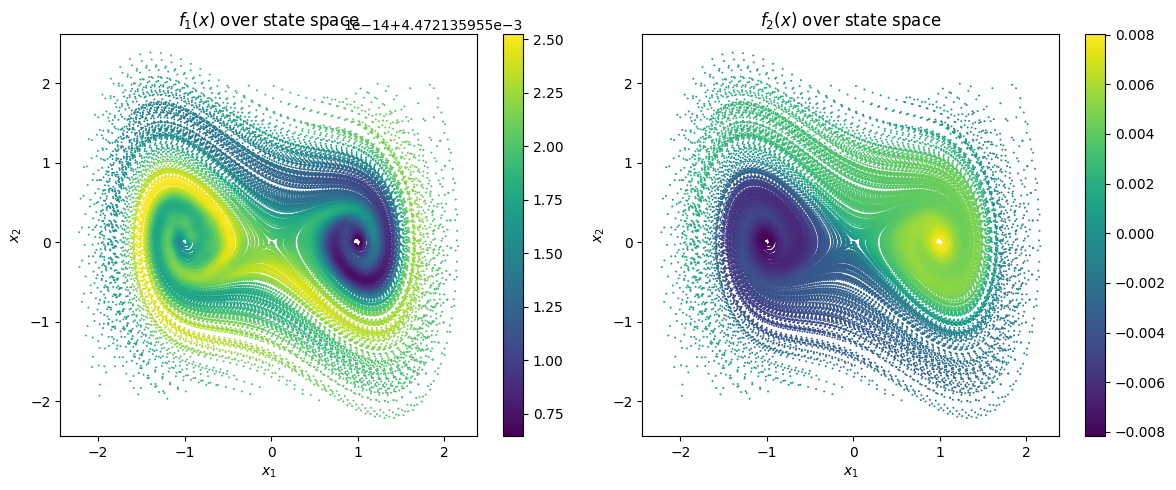

In [5]:
t0 = time.time()
emb = compute_embedding(PAPER["gamma"])
print(f"gamma = {PAPER['gamma']}: r = {emb['eigvals'].size} invariant modes, eigenvalues {emb['eigvals']}  ({time.time() - t0:.1f}s)")

_ = plot_invariant_scalar_histograms(emb["F_X"], emb["eigvals"], title="GEP invariant scalar observables on the training data")
_ = plot_invariant_embedding_2d(emb["F_X"], title=r"Invariant embedding $(f_1(x), f_2(x))$")

fig, axes = plt.subplots(1, emb["F_X"].shape[1], figsize=(6 * emb["F_X"].shape[1], 5), squeeze=False)
for j, ax in enumerate(axes[0]):
    sc = ax.scatter(X[:, 0], X[:, 1], s=2, c=emb["F_X"][:, j], cmap="viridis", edgecolors="none")
    fig.colorbar(sc, ax=ax); ax.set_title(rf"$f_{j + 1}(x)$ over state space"); ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
plt.tight_layout(); plt.show()

The first mode is the constant function ($\lambda_1 \approx 10^{-16}$, a spike in the histogram),
which is why its cluster count must be `1` in `scalar_cluster_count`. The second mode is the
interesting one: it is nearly piecewise constant in state space, taking one plateau value on each
basin, with the transition region concentrated along the boundary between them. Everything that
follows is about turning that plateau structure into a labeled partition.

## 2. Scalar clustering and fine cells ($k_1, \ldots, k_r$)

Each coordinate $f_j(x)$ is clustered independently with 1-D $k$-means into $k_j$ groups; the
tuple of scalar labels is the *fine cell* of $x$. We keep $k_1 = 1$ for the constant mode and sweep
$k_2$. The plots show the fine cells **before any merging** (each color is one fine cell); the
table shows how each choice fares after the paper's merge thresholds are applied.

The non-constant coordinate $f_2(x)$ is roughly symmetric about the value it takes on the separatrix. With an **even** $k$, 1-D $k$-means places a cluster boundary at that symmetry point, so every fine cell lies inside one basin. With an **odd** $k$ the middle cluster is *centred* on the separatrix and straddles both basins: snapshots in it transition to both attractors, so it acts as a bridge and the transition merge collapses the whole partition to a single cell (validation is then impossible because both anchors land in the same cell). This is the parity effect mentioned in the remark.

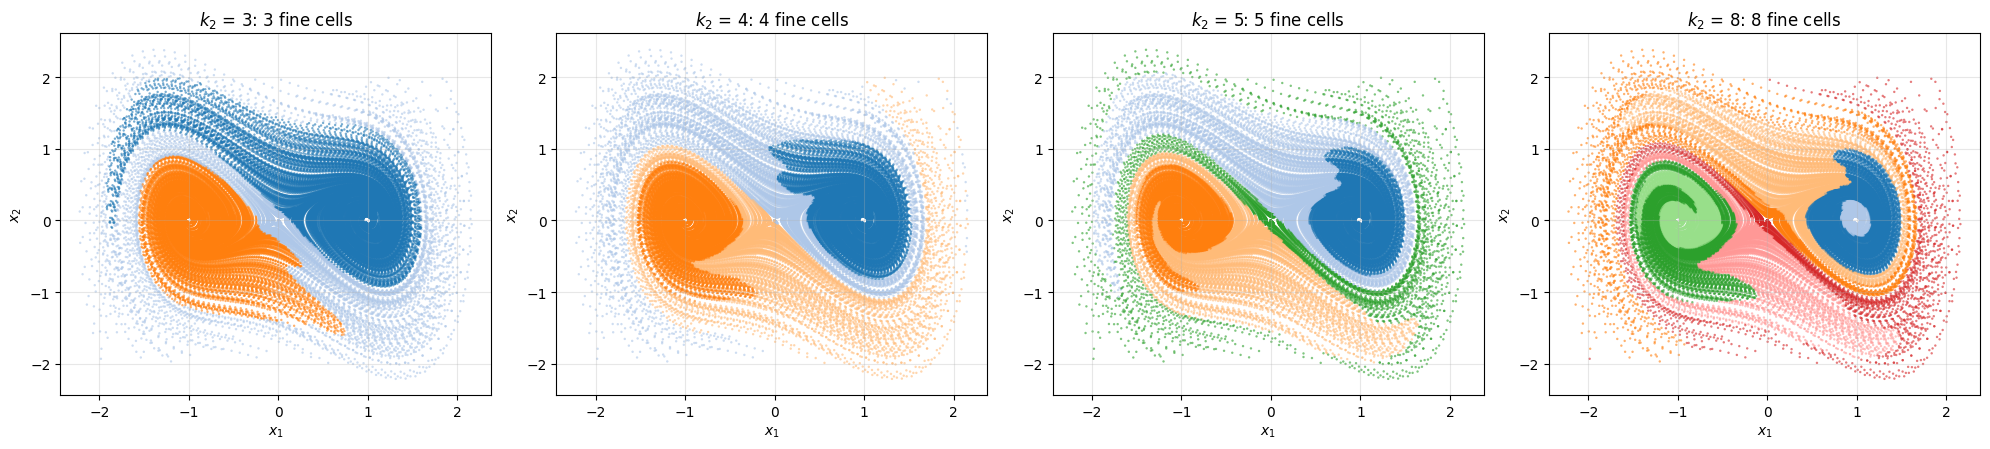

,occupied,retained,after_tau_tr,final,train_dropped,val_accuracy,val_dropped
k_2,,,,,,,
2,2,2,2,2,0.0,0.99847,0.00000
3,3,3,1,1,0.0,NaN,NaN
4,4,4,2,2,0.0,0.99862,0.00000
5,5,5,1,1,0.0,NaN,NaN
6,6,6,2,2,0.0,0.99951,0.00000
8,8,8,3,3,0.0,0.99922,0.13308


In [6]:
k_grid = [2, 3, 4, 5, 6, 8]
k_show = [3, 4, 5, 8]

fig, axes = plt.subplots(1, len(k_show), figsize=(5 * len(k_show), 4.6))
for ax, k in zip(axes, k_show):
    result, _ = fit_partition(emb, n_clusters=[1, k])
    scatter_cells(ax, result["cell_ids_X"], rf"$k_2$ = {k}: {result['n_occupied_fine_cells']} fine cells")
plt.tight_layout(); plt.show()

table_k = sweep(emb, "n_clusters", [[1, k] for k in k_grid])
table_k.index = pd.Index(k_grid, name="k_2")
table_k

Per row: number of occupied fine cells, cells surviving the occupancy filter, nodes after the
transition merge, final cells, fraction of training points dropped, and validation accuracy on
un-dropped points / fraction of validation points dropped (NaN = validation impossible because
the partition collapsed to one cell).

## 3. Occupancy filter ($\tau_{\mathrm{occ}}$)

Fine cells with empirical weight $|C_\alpha| / N < \tau_{\mathrm{occ}}$ are dropped before the
transition graph is built. The transition merge compares an empirical *probability*
$p_{ab} = n_{ab} / n_a$ with $\tau_{\mathrm{tr}}$, so a cell with only a handful of points can
produce a large $p_{ab}$ from one or two stray transitions and bridge two basins;
$\tau_{\mathrm{occ}}$ is a minimum-count guard on that denominator
(see `plotting/tau_occ_sensitivity.md`).

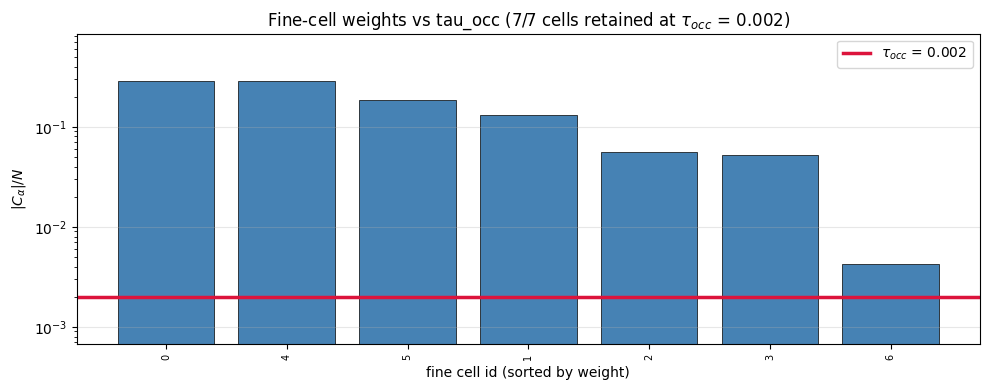

,occupied,retained,after_tau_tr,final,train_dropped,val_accuracy,val_dropped
tau_occ,,,,,,,
0.0000,7,7,2,2,0.00000,0.99862,0.00000
0.0005,7,7,2,2,0.00000,0.99862,0.00000
0.0020,7,7,2,2,0.00000,0.99862,0.00000
0.0100,7,6,2,2,0.00428,0.99849,0.08702
0.0500,7,6,2,2,0.00428,0.99849,0.08702


In [7]:
result_paper_k, _ = fit_partition(emb)
_ = plot_cell_weights(result_paper_k["cell_weights"], PAPER["tau_occ"])

table_occ = sweep(emb, "tau_occ", [0.0, 0.0005, 0.002, 0.01, 0.05])
table_occ

With the paper's $k_2$ every fine cell is well populated, so on the grid above
$\tau_{\mathrm{occ}}$ either does nothing or, once raised well above its paper value, removes
cells that *should* be kept (their points then count as dropped). It becomes important with larger
$k_j$ or higher-dimensional embeddings, where thin cells along the boundary appear — the paper value
is a safety margin for that situation rather than an active constraint here. The next cell makes
that situation happen on purpose.

### When $\tau_{\mathrm{occ}}$ is essential

To see the guard in action we keep the paper embedding but make the fine partition much finer, $k_2 = 64$, so that $f_2$ is sliced into thin strips and the strip that contains the separatrix holds well under 1% of the data. Transition merging is set to a value inside the plateau found in section 4 ($\tau_{\mathrm{tr}} = 0.01$, $\tau_{\mathrm{val}} = 0$).

,occupied,retained,after_tau_tr,final,train_dropped,val_accuracy,val_dropped
tau_occ,,,,,,,
0.000,64,64,1,1,0.00000,NaN,NaN
0.002,64,64,1,1,0.00000,NaN,NaN
0.004,64,64,1,1,0.00000,NaN,NaN
0.005,64,63,2,2,0.00452,0.99984,0.00126
0.007,64,55,2,2,0.05198,NaN,NaN
0.010,64,42,2,2,0.16390,NaN,NaN
0.020,64,23,4,4,0.46048,NaN,NaN


smallest usable tau_occ on the grid: 0.005; it removes 1 of 64 fine cells


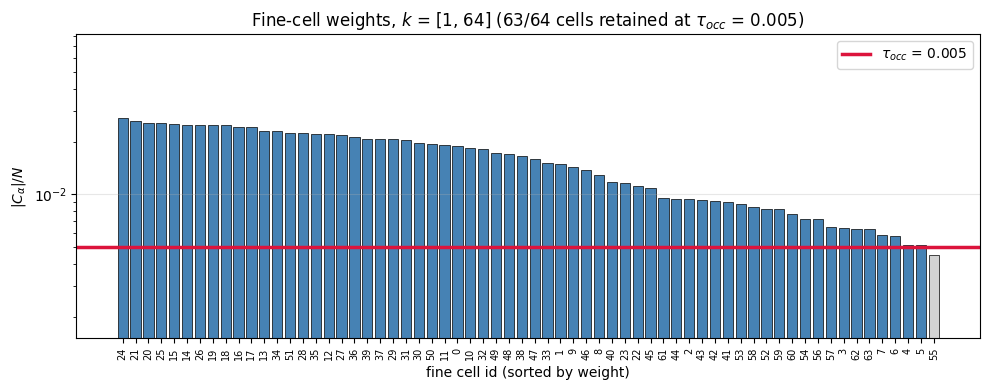

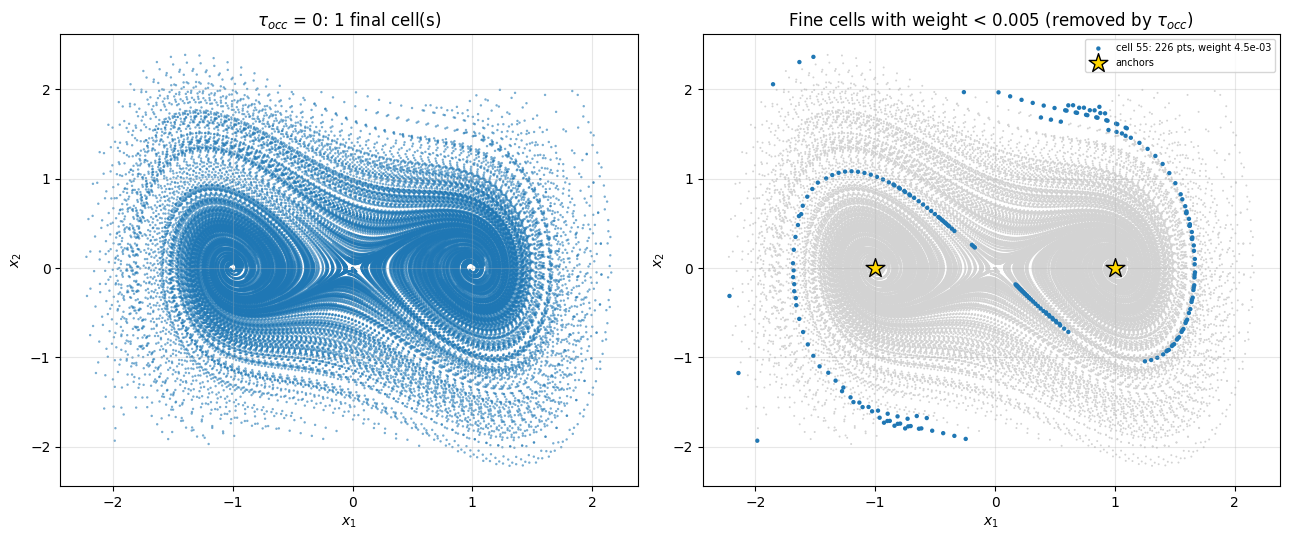

In [8]:
OCC_DEMO = dict(n_clusters=[1, 64], tau_tr=0.01, tau_val=0.0)
tau_occ_demo = [0.0, 0.002, 0.004, 0.005, 0.007, 0.01, 0.02]

emb_demo = emb   # same embedding as the paper (gamma = 30, r = 2)
table_occ_demo = sweep(emb_demo, "tau_occ", tau_occ_demo, **OCC_DEMO)
display(table_occ_demo)

# smallest tau_occ on the grid that yields a usable two-cell partition
usable = table_occ_demo.index[(table_occ_demo["final"] == 2) & table_occ_demo["val_accuracy"].notna()]
TAU_OK = float(usable[0])

result_occ0, _ = fit_partition(emb_demo, tau_occ=0.0, **OCC_DEMO)
weights = result_occ0["cell_weights"]
thin_cells = sorted((cid for cid, w in weights.items() if w < TAU_OK), key=lambda cid: weights[cid])
print(f"smallest usable tau_occ on the grid: {TAU_OK:g}; it removes {len(thin_cells)} of {len(weights)} fine cells")

_ = plot_cell_weights(weights, TAU_OK, title=rf"Fine-cell weights, $k$ = {OCC_DEMO['n_clusters']}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
scatter_cells(axes[0], result_occ0["final_labels_X"],
              rf"$\tau_{{occ}}$ = 0: {len(result_occ0['components'])} final cell(s)")
axes[1].scatter(X[:, 0], X[:, 1], s=2, c="lightgray", edgecolors="none")
for cid in thin_cells:
    mask = result_occ0["cell_ids_X"] == cid
    axes[1].scatter(X[mask, 0], X[mask, 1], s=10, edgecolors="none",
                    label=f"cell {cid}: {int(mask.sum())} pts, weight {weights[cid]:.1e}")
axes[1].scatter(anchors[:, 0], anchors[:, 1], s=200, marker="*", c="gold", edgecolors="black", zorder=5, label="anchors")
axes[1].set_title(rf"Fine cells with weight < {TAU_OK:g} (removed by $\tau_{{occ}}$)")
axes[1].set_xlabel("$x_1$"); axes[1].set_ylabel("$x_2$"); axes[1].grid(alpha=0.3); axes[1].legend(fontsize=7, loc="upper right")
plt.tight_layout(); plt.show()

With $\tau_{\mathrm{occ}} = 0$ the partition collapses to a single cell. The culprit is one fine cell of ~225 points (weight $4.5 \times 10^{-3}$) lying exactly on the separatrix: its points flow to both attractors, so with only a couple of hundred samples in the denominator of $p_{ab}$ it has transition probability above $\tau_{\mathrm{tr}}$ into *both* basins and joins them. Setting $\tau_{\mathrm{occ}} = 0.005$ removes exactly that cell and the two basins reappear with 99.98% validation accuracy and 0.1% dropped. Pushing $\tau_{\mathrm{occ}}$ further removes legitimate cells, first inflating the dropped fraction and then removing the cell that contains an anchor, at which point validation is impossible again. The usable window is narrow here because $k_2 = 64$ is an unreasonably fine partition; with the paper's $k_2 = 4$ the same guard is simply inactive.

## 4. Transition-based merging ($\tau_{\mathrm{tr}}$, with $\tau_{\mathrm{val}} = 0$)

Following the remark we first switch value-based merging off ($\tau_{\mathrm{val}} = 0$) and
sweep $\tau_{\mathrm{tr}}$. Two retained fine cells $a, b$ are joined when
$\max(p_{ab}, p_{ba}) \ge \tau_{\mathrm{tr}}$, and the final cells are the connected components
of that graph. The first plot shows the pairwise transition scores against the threshold; the
second shows how the number of final cells and the validation accuracy move with it.

inter-cell transition scores max(p_ab, p_ba), descending: [1.      1.      0.95799 0.04201 0.0174  0.01055 0.00392 0.      0.
 0.      0.      0.      0.      0.      0.      0.      0.      0.
 0.      0.      0.     ]


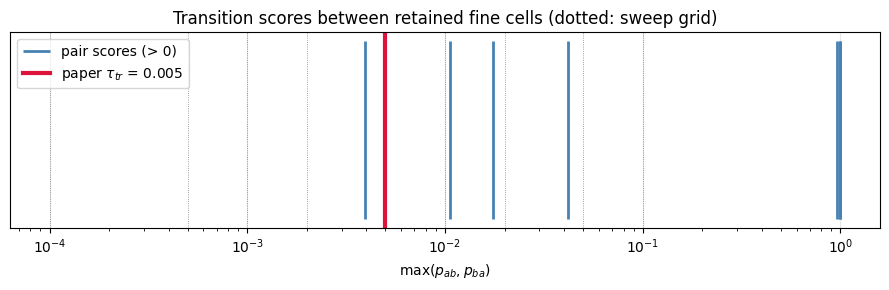

,occupied,retained,after_tau_tr,final,train_dropped,val_accuracy,val_dropped
tau_tr,,,,,,,
0.0001,7,7,1,1,0.0,NaN,NaN
0.0005,7,7,1,1,0.0,NaN,NaN
0.0010,7,7,1,1,0.0,NaN,NaN
0.0020,7,7,1,1,0.0,NaN,NaN
0.0050,7,7,2,2,0.0,0.99862,0.00000
0.0100,7,7,2,2,0.0,0.99862,0.00000
0.0200,7,7,3,3,0.0,0.99856,0.04259
0.0500,7,7,4,4,0.0,1.00000,0.08265
0.1000,7,7,4,4,0.0,1.00000,0.08265


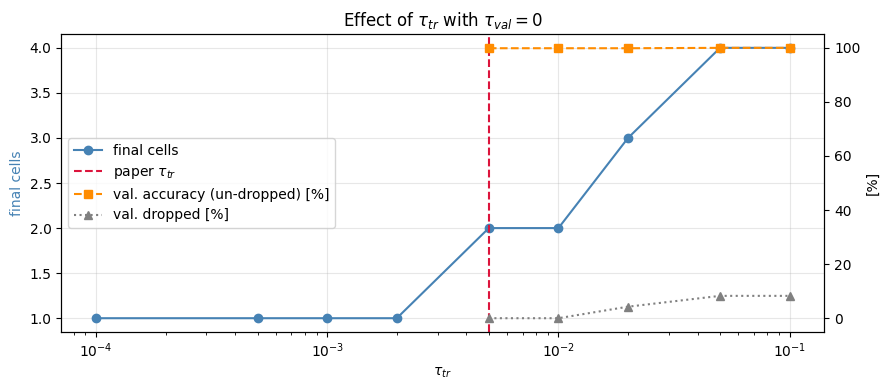

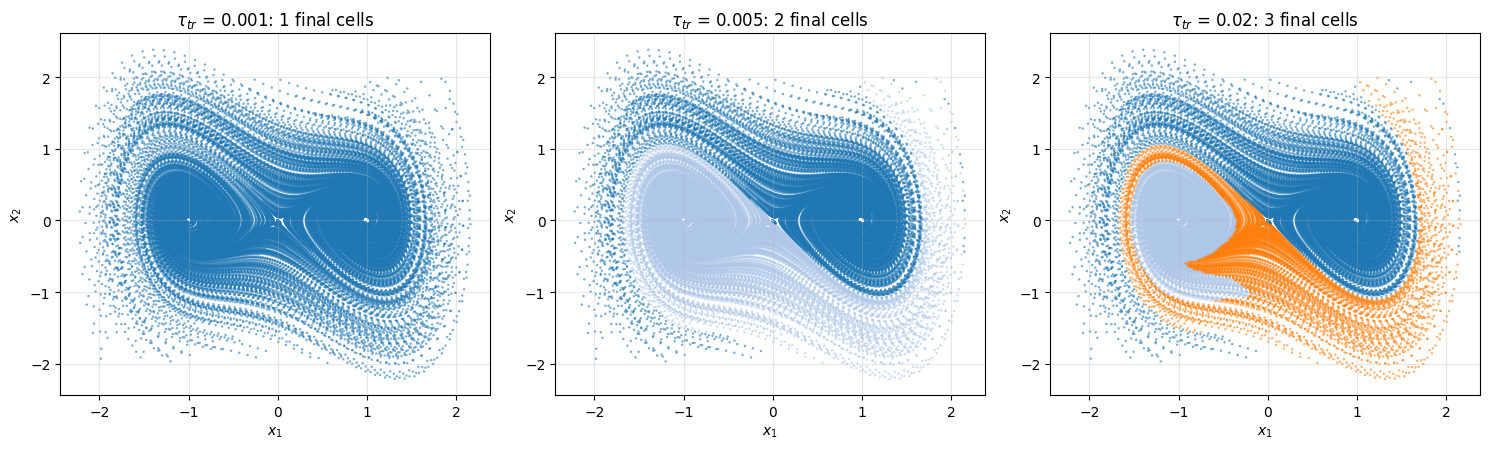

In [9]:
tau_tr_grid = [0.0001, 0.0005, 0.001, 0.002, 0.005, 0.01, 0.02, 0.05, 0.1]

result_tr0, _ = fit_partition(emb, tau_val=0.0)
scores = np.sort(np.asarray(result_tr0["transition_pair_scores"]))[::-1]
print("inter-cell transition scores max(p_ab, p_ba), descending:", np.round(scores, 5))

fig, ax = plt.subplots(figsize=(9, 3))
ax.vlines(scores[scores > 0], 0, 1, colors="steelblue", lw=2, label="pair scores (> 0)")
for t in tau_tr_grid:
    ax.axvline(t, color="gray", lw=0.6, ls=":")
ax.axvline(PAPER["tau_tr"], color="crimson", lw=3, label=rf"paper $\tau_{{tr}}$ = {PAPER['tau_tr']}")
ax.set_xscale("log"); ax.set_yticks([]); ax.set_xlabel(r"$\max(p_{ab}, p_{ba})$")
ax.set_title("Transition scores between retained fine cells (dotted: sweep grid)")
ax.legend(loc="upper left"); ax.grid(axis="x", alpha=0.3)
plt.tight_layout(); plt.show()

table_tr = sweep(emb, "tau_tr", tau_tr_grid, tau_val=0.0)
display(table_tr)

fig, ax1 = plt.subplots(figsize=(9, 4))
ax1.plot(table_tr.index, table_tr["final"], "o-", color="steelblue", label="final cells")
ax1.set_xscale("log"); ax1.set_xlabel(r"$\tau_{tr}$"); ax1.set_ylabel("final cells", color="steelblue")
ax1.axvline(PAPER["tau_tr"], color="crimson", ls="--", label=r"paper $\tau_{tr}$")
ax2 = ax1.twinx()
ax2.plot(table_tr.index, 100 * table_tr["val_accuracy"], "s--", color="darkorange", label="val. accuracy (un-dropped) [%]")
ax2.plot(table_tr.index, 100 * table_tr["val_dropped"], "^:", color="gray", label="val. dropped [%]")
ax2.set_ylabel("[%]")
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="center left"); ax1.grid(alpha=0.3)
ax1.set_title(r"Effect of $\tau_{tr}$ with $\tau_{val} = 0$")
plt.tight_layout(); plt.show()

tau_tr_show = [0.001, 0.005, 0.02]
fig, axes = plt.subplots(1, len(tau_tr_show), figsize=(5 * len(tau_tr_show), 4.6))
for ax, t in zip(axes, tau_tr_show):
    result, _ = fit_partition(emb, tau_tr=t, tau_val=0.0)
    scatter_cells(ax, result["final_labels_X"], rf"$\tau_{{tr}}$ = {t:g}: {len(result['components'])} final cells")
plt.tight_layout(); plt.show()

For $\tau_{\mathrm{tr}} \lesssim 0.003$ the partition collapses to one cell: the weakest inter-cell transition score (~0.003, the leak across the separatrix) is enough to join everything. Between about $0.005$ and $0.01$ the partition is *stationary* with two persistent cells — this is the plateau the remark says to look for. Above $0.02$ nothing merges and the four fine cells survive; validation accuracy is still perfect on the two anchored cells, but the other two are unmapped and their ~8% of validation samples count as dropped.

## 5. Value-based merging ($\tau_{\mathrm{val}}$)

With $\tau_{\mathrm{tr}}$ fixed at its paper value, the transition-merged nodes are compared by
the distance between their centroids in embedding space, $\|m_\alpha - m_\beta\|_2$, and joined
when it is below $\tau_{\mathrm{val}}$.

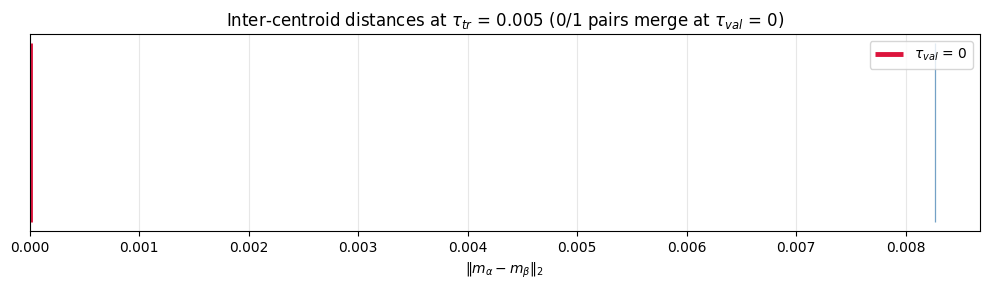

,occupied,retained,after_tau_tr,final,train_dropped,val_accuracy,val_dropped
tau_val,,,,,,,
0.000,7,7,2,2,0.0,0.99862,0.0
0.002,7,7,2,2,0.0,0.99862,0.0
0.004,7,7,2,2,0.0,0.99862,0.0
0.006,7,7,2,2,0.0,0.99862,0.0
0.010,7,7,2,1,0.0,NaN,NaN
0.020,7,7,2,1,0.0,NaN,NaN


In [10]:
result_paper_tr, _ = fit_partition(emb, tau_val=0.0)
_ = plot_inter_centroid_distances(result_paper_tr["centroid_pair_distances"], PAPER["tau_val"],
                                  title=rf"Inter-centroid distances at $\tau_{{tr}}$ = {PAPER['tau_tr']}")

table_val = sweep(emb, "tau_val", [0.0, 0.002, 0.004, 0.006, 0.01, 0.02])
table_val

With $\tau_{\mathrm{tr}}$ fixed there is only one pair of transition-merged nodes left, at centroid distance ~0.008, so $\tau_{\mathrm{val}}$ is inert until it exceeds that value, at which point the two basins merge and the partition fails. For Duffing transition-based merging alone is sufficient, which is the typical situation described in the remark.

## 6. Final partition with the paper parameters

Putting the choices together (no robustness margin yet).

occupied         7.0
retained         7.0
after_tau_tr     2.0
final            2.0
train_dropped    0.0
merge edges: 6 transition, 0 value


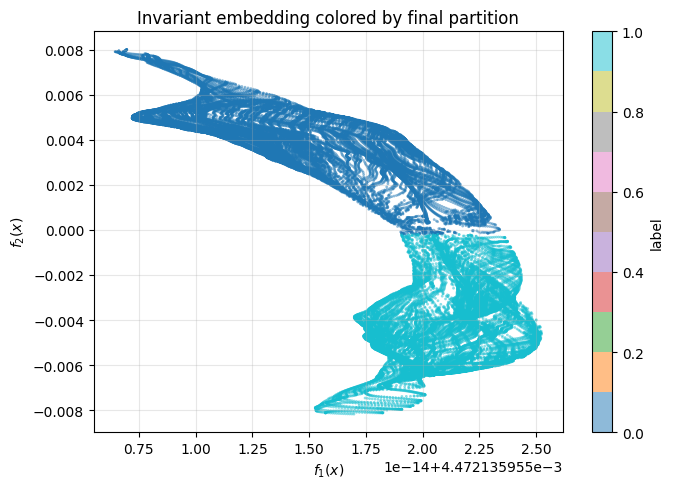

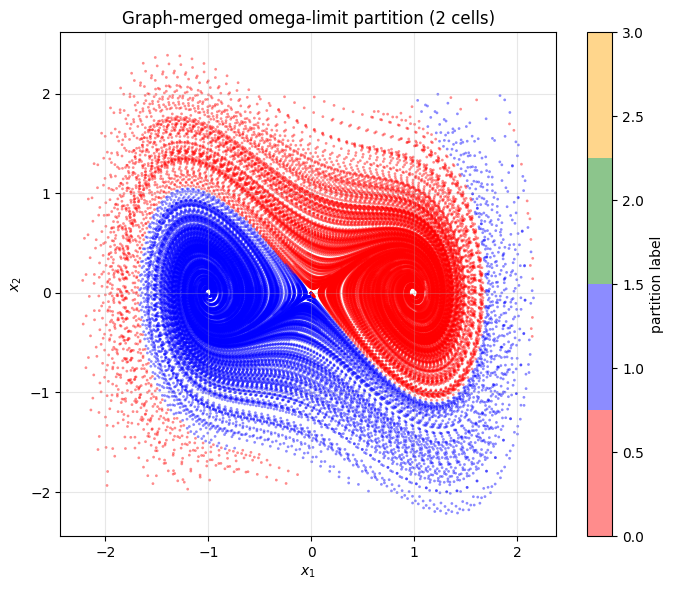

In [11]:
result, inference = fit_partition(emb)
print(pd.Series({k: v for k, v in summarize(result).items() if not k.startswith("val_")}).to_string())
print("merge edges:", len(result["merge_edges_transition"]), "transition,", len(result["merge_edges_value"]), "value")

_ = plot_invariant_embedding_2d(emb["F_X"], labels=result["final_labels_X"], title="Invariant embedding colored by final partition")
_ = plot_state_partition_2d(X, result["final_labels_X"], title=f"Graph-merged omega-limit partition ({len(result['components'])} cells)")

## 7. Validation against labeled trajectories

A partition label is just an integer; to score it we need to know which label corresponds to which
attractor. Each class anchor is classified by the partition, which gives the map
partition id $\to$ class, and every validation snapshot is then scored by whether it lands in the
same partition cell as its trajectory's eventual attractor.

For Duffing the anchors are the two stable equilibria $(\mp 1, 0)$ given inline as `target_equilibria` in `configs/duffing/validate_partition.json`.

Anchor assignments:
  class 0: state=(-1, 0) -> partition 1
  class 1: state=(1, 0) -> partition 0
Predicted partition labels (excluding dropped): [0, 1]

+----------------------+---------------------+----------------------------+---------+--------+--------+
| Method               | Anchor mapping      | Metric                     | Correct | Total  | Rate   |
+======================+=====================+============================+=========+========+========+
| GraphMergedPartition | anchor (0->1, 1->0) | accuracy (total data)      | 398651  | 399200 | 99.86% |
| GraphMergedPartition | anchor (0->1, 1->0) | accuracy (un-dropped data) | 398651  | 399200 | 99.86% |
| GraphMergedPartition | anchor (0->1, 1->0) | dropped predictions        | 0       | 399200 | 0.00%  |
+----------------------+---------------------+----------------------------+---------+--------+--------+


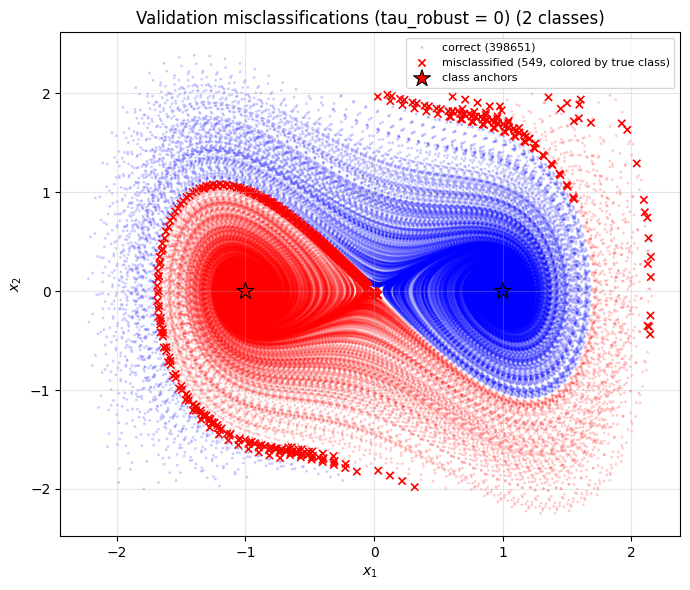

In [12]:
res = validate(emb, inference)
print_anchor_assignments(res.anchors, res.anchor_partitions, pred_raw=res.pred_raw)
print()
print_classification_table(res.table_rows)

_ = plot_misclassified_points(X_val, res.gt_labels, res.pred_mapped, anchors=res.anchors,
                              title="Validation misclassifications (tau_robust = 0)")

The errors, when there are any, sit along the boundary between the basins (and near the edge of
the sampled domain where the RBF dictionary runs out of centers). We can quantify "near the
boundary" in the embedding: for each coordinate $f_j$, the distance from $f_j(x)$ to the nearest
cluster boundary *at which the final label changes*, divided by the length of the merged region
along $f_j$; then the minimum over $j$. Misclassified samples should have a small value of this
relative distance, correctly classified ones should not.

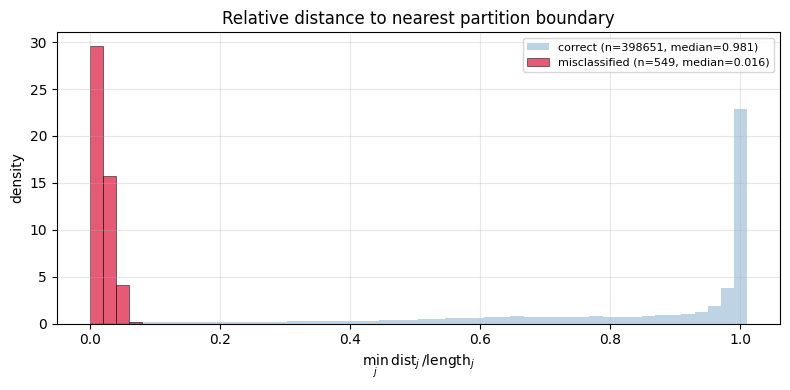

misclassified: n=    549  median=0.0160  frac < 0.05 = 0.982
      correct: n= 398651  median=0.9815  frac < 0.05 = 0.003


In [13]:
rel_dist, _ = compute_relative_boundary_distances(emb["F_val"], inference)
misclassified = (res.pred_mapped >= 0) & (res.pred_mapped != res.gt_labels)
_ = plot_boundary_distance_histogram(rel_dist, misclassified, baseline_mask=res.correct_mask)

for name, mask in (("misclassified", misclassified), ("correct", res.correct_mask)):
    vals = rel_dist[mask & np.isfinite(rel_dist)]
    if vals.size:
        print(f"{name:>13}: n={vals.size:7d}  median={np.median(vals):.4f}  frac < 0.05 = {np.mean(vals < 0.05):.3f}")
    else:
        print(f"{name:>13}: n=0")

### Robustness margin ($\tau_{\mathrm{robust}}$)

Because the errors are concentrated near the boundary, dropping every point whose relative boundary
distance is below $\tau_{\mathrm{robust}}$ trades a small fraction of *dropped* predictions for a
higher accuracy on the points that are classified. The margin is stored with the partition and
applied identically to training and validation data.

,occupied,retained,after_tau_tr,final,train_dropped,val_accuracy,val_dropped
tau_robust,,,,,,,
0.00,7,7,2,2,0.00000,0.99862,0.00000
0.02,7,7,2,2,0.00782,0.99945,0.00162
0.05,7,7,2,2,0.01804,0.99997,0.00424
0.10,7,7,2,2,0.04458,1.00000,0.00997
0.20,7,7,2,2,0.10320,1.00000,0.02314
0.30,7,7,2,2,0.18098,1.00000,0.04018


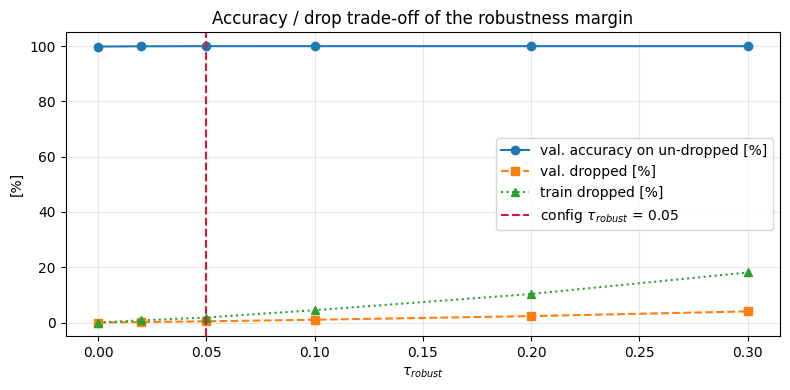

In [14]:
tau_robust_grid = [0.0, 0.02, 0.05, 0.1, 0.2, 0.3]
table_robust = sweep(emb, "tau_robust", tau_robust_grid)
display(table_robust)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(tau_robust_grid, 100 * table_robust["val_accuracy"], "o-", label="val. accuracy on un-dropped [%]")
ax.plot(tau_robust_grid, 100 * table_robust["val_dropped"], "s--", label="val. dropped [%]")
ax.plot(tau_robust_grid, 100 * table_robust["train_dropped"], "^:", label="train dropped [%]")
ax.axvline(PAPER["tau_robust"], color="crimson", ls="--", label=rf"config $\tau_{{robust}}$ = {PAPER['tau_robust']}")
ax.set_xlabel(r"$\tau_{robust}$"); ax.set_ylabel("[%]"); ax.grid(alpha=0.3); ax.legend()
ax.set_title("Accuracy / drop trade-off of the robustness margin")
plt.tight_layout(); plt.show()

tau_robust = 0.05
+----------------------+---------------------+----------------------------+---------+--------+---------+
| Method               | Anchor mapping      | Metric                     | Correct | Total  | Rate    |
+======================+=====================+============================+=========+========+=========+
| GraphMergedPartition | anchor (0->1, 1->0) | accuracy (total data)      | 397498  | 399200 | 99.57%  |
| GraphMergedPartition | anchor (0->1, 1->0) | accuracy (un-dropped data) | 397498  | 397508 | 100.00% |
| GraphMergedPartition | anchor (0->1, 1->0) | dropped predictions        | 1692    | 399200 | 0.42%   |
+----------------------+---------------------+----------------------------+---------+--------+---------+


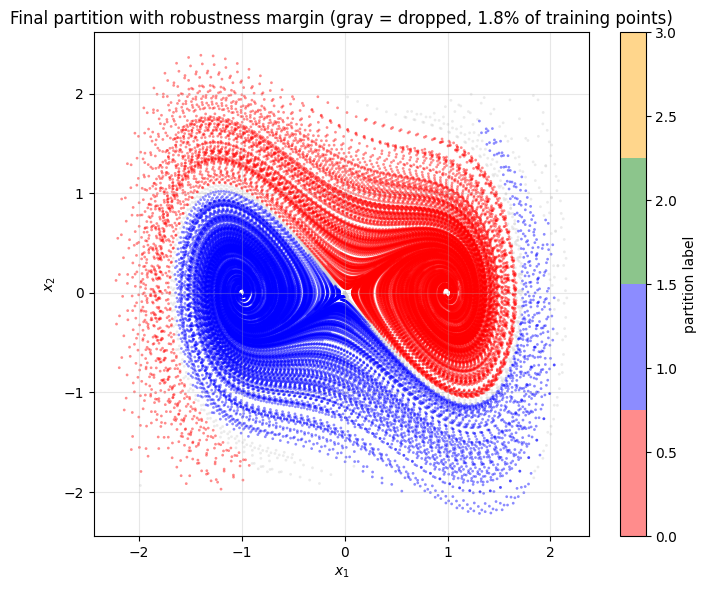

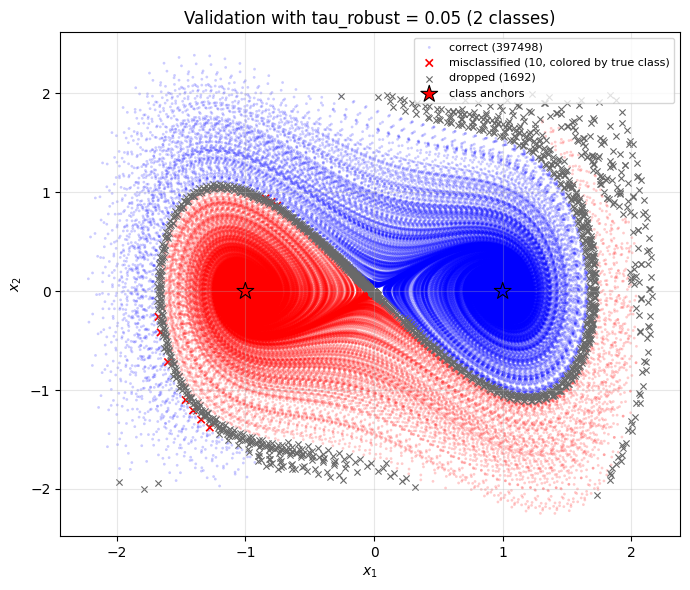

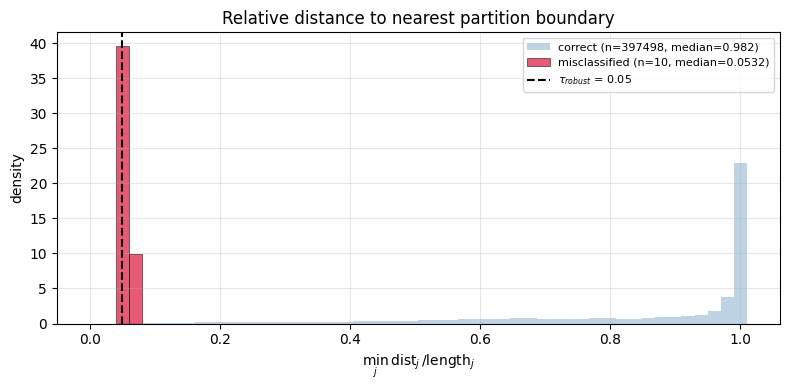

In [15]:
TAU_ROBUST = PAPER["tau_robust"] if PAPER["tau_robust"] > 0 else 0.05
result_final, inference_final = fit_partition(emb, tau_robust=TAU_ROBUST)
res_final = validate(emb, inference_final)
print(f"tau_robust = {TAU_ROBUST}")
print_classification_table(res_final.table_rows)

_ = plot_state_partition_2d(X, result_final["final_labels_X"],
                            title=f"Final partition with robustness margin (gray = dropped, {100 * np.mean(result_final['final_labels_X'] < 0):.1f}% of training points)")
_ = plot_misclassified_points(X_val, res_final.gt_labels, res_final.pred_mapped, anchors=res_final.anchors,
                              title=f"Validation with tau_robust = {TAU_ROBUST}")
rel_dist_final, _ = compute_relative_boundary_distances(emb["F_val"], inference_final)
misclassified_final = (res_final.pred_mapped >= 0) & (res_final.pred_mapped != res_final.gt_labels)
_ = plot_boundary_distance_histogram(rel_dist_final, misclassified_final, baseline_mask=res_final.correct_mask,
                                     tau_robust=TAU_ROBUST)

The margin removes a thin band around the boundary (gray in the state-space plot). Every remaining
misclassification, if any, lies just outside that band — the histogram's red bars start at
$\tau_{\mathrm{robust}}$ — and the classified points are scored at (or very near) 100%.

## Summary

| stage | parameter | what the sweep showed |
|---|---|---|
| GEP | $\gamma$ | too small: spurious near-zero eigenvalues from an ill-conditioned dictionary; too large: only the constant survives; pick the smallest $\gamma$ that gives $m$ modes below $\epsilon$ with a gap |
| fine cells | $k_j$ | must be `1` for the constant mode; parity and size of $k_2$ decide whether a fine cell straddles the boundary, which the merge steps then cannot undo |
| occupancy | $\tau_{\mathrm{occ}}$ | inactive at the paper $k_j$ (every cell is well populated), but **essential** as soon as the fine partition has thin cells: a single low-count cell that straddles the boundary transitions into both basins and collapses the partition unless $\tau_{\mathrm{occ}}$ removes it |
| transition merge | $\tau_{\mathrm{tr}}$ | collapse below a threshold, then a stationary plateau with the right number of cells, then no merging |
| value merge | $\tau_{\mathrm{val}}$ | secondary refinement; too large merges across the true boundary |
| margin | $\tau_{\mathrm{robust}}$ | trades a small dropped fraction for near-perfect accuracy on the rest |

**Learnings about $\tau_{\mathrm{occ}}$.** The occupancy filter is not a cosmetic clean-up of small
cells; it is a minimum-count guard on the denominator of the empirical transition probability
$p_{ab} = n_{ab} / n_a$. Whether it matters is decided by the fine partition, not by the system:
with few, well-populated cells (the paper's $k_j$) it does nothing, while with a fragmented fine
partition (large $k_j$, or several invariant modes) the thinnest cells are exactly the ones lying on
the boundary between basins, and each of them needs only a couple of stray transitions to exceed
$\tau_{\mathrm{tr}}$ in both directions. The right value sits just above the weight of those
straddling cells and well below the weight of genuine cells — a window that is wide for a sensible
$k_j$ and narrow for an excessive one — so $\tau_{\mathrm{occ}}$ should be tuned together with
$k_j$, and kept at a non-zero value as insurance even when the current settings do not need it.

The same experiment can be reproduced from the command line with
`python scripts/build_partition.py configs/<system>/build_partition.json` followed by
`python scripts/validate_partition.py configs/<system>/validate_partition.json`.

## 8. Switched local EDMD models vs vanilla EDMD

With the partition fixed (`inference_final`: the config parameters plus the robustness margin), we now
build the prediction models of `scripts/build_multiple_linear_models.py`:

* **switched EDMD** — one local EDMD model $(K_\ell, R_\ell)$ per partition cell, fitted on the snapshot
  pairs the partition assigns to that cell; pairs the partition drops (label $-1$, i.e. inside the
  $\tau_{\mathrm{robust}}$ band) are *excluded* from the fit;
* **vanilla EDMD** — a single global model $(K, R)$ fitted on *all* snapshot pairs with the *same*
  dictionary object (same RBF centers, same $\gamma$, same polynomial degree).

Both use the same dictionary $\Psi$ and are rolled out the same way: the initial condition is lifted
once, $z_0 = \Psi(x_0)$, the lifted state is propagated linearly, $z_{t+1} = z_t K$ (with $K = K_\ell$
for the cell of $x_0$; `reclassify_each_step = false`), and $x_t = z_t R$ is decoded for storage only —
the decoded state is never re-lifted. This is the honest linear-Koopman rollout; it exposes how far
the span of $\Psi$ is from being $K$-invariant, which a chained one-step predictor would hide.

To keep this cheap we evaluate only on the initial conditions in `ICs_phase_plot`
(`run_gated_evaluation = false` in the config). The classification-gated evaluation on the full
validation set is what the script prints when that flag is `true`.

In [16]:
sys.path.insert(0, str(PROJECT_ROOT / "scripts"))
import build_multiple_linear_models as bmlm
from src_omega_partition.dictionary import sample_edmd_centers
from src_omega_partition.partition import classify_partition_labels
from src_omega_partition.switched_models import fit_switched_edmd_models, fit_vanilla_edmd_model

mlm_cfg = bmlm.load_settings(PROJECT_ROOT / f"configs/{SYSTEM}/build_multiple_linear_models.json")
mlm_cfg["run_gated_evaluation"] = False   # IC rollouts only; the gated validation-set evaluation takes minutes
EDMD = {k: mlm_cfg[k] for k in ("edmd_gamma", "edmd_d_poly", "number_centers_edmd", "prediction_horizon",
                                "reclassify_each_step", "ICs_phase_plot", "rollout_rel_rmse_times")}
display(pd.Series({k: str(v) for k, v in EDMD.items()}, name="config value").to_frame())

fit_data = np.load(resolve(mlm_cfg["data_path"]))
X_fit, Y_fit = fit_data["X"], fit_data["Y"]
traj_fit = fit_data["trajectories"] if "trajectories" in fit_data else None
labels_fit = classify_partition_labels(X_fit, inference_final)
print(f"EDMD fit data: {mlm_cfg['data_path']} ({X_fit.shape[0]} pairs); "
      f"partition-dropped: {np.sum(labels_fit < 0)} ({100 * np.mean(labels_fit < 0):.2f}%) -> excluded from the switched fit only")

phase_true, horizon = bmlm._phase_plot_true_trajectories(traj_fit, mlm_cfg, n_state=n)
print(f"{phase_true.shape[0]} test trajectories of {horizon} steps from x0 = {[np.round(x, 3).tolist() for x in phase_true[:, 0]]}")


def build_edmd_models(gamma, d_poly, n_centers, *, partition=inference_final, labels=labels_fit):
    '''Local EDMD per partition cell (dropped pairs excluded) + one vanilla EDMD on all pairs, same dictionary.
    n_centers = 0 gives a polynomial-only dictionary.'''
    centers = sample_edmd_centers(centers_global, n_centers, random_state=mlm_cfg["random_state"], verbose=False)
    Phi = build_rbf_polynomial_dictionary(n, centers, gamma, d_poly)
    switched = fit_switched_edmd_models(X_fit, Y_fit, labels, Phi, min_samples=mlm_cfg["min_samples_per_cell"])
    vanilla = fit_vanilla_edmd_model(X_fit, Y_fit, Phi)
    return Phi, switched, vanilla


def rollout_ics(Phi, switched, vanilla, *, partition=inference_final):
    '''Lift once, propagate in the lifted space, decode for storage (switched_koopman_rollout / vanilla_koopman_rollout).'''
    sw = bmlm._rollouts_from_trajectories(phase_true, horizon, bmlm._switched_rollout_fn(switched, partition, Phi, mlm_cfg))
    van = bmlm._rollouts_from_trajectories(phase_true, horizon, bmlm._vanilla_rollout_fn(vanilla, Phi))
    return sw, van, bmlm._metrics_from_rollouts(sw, horizon, mlm_cfg), bmlm._metrics_from_rollouts(van, horizon, mlm_cfg)


def spectral_radius(K):
    return float(np.max(np.abs(np.linalg.eigvals(K))))


rng_onestep = np.random.default_rng(0)
onestep_idx = rng_onestep.choice(X_fit.shape[0], size=min(20000, X_fit.shape[0]), replace=False)

def onestep_state_rel_err(Phi, switched, vanilla):
    '''In-sample one-step relative state error on a 20k subsample of the fit pairs (switched: per-cell operator).'''
    Xs, Ys, ls = X_fit[onestep_idx], Y_fit[onestep_idx], labels_fit[onestep_idx]
    sw = []
    for l, K in switched["K_by_label"].items():
        m = ls == l
        if m.any():
            sw.append(bmlm._one_step_sample_errors(Xs[m], Ys[m], K, switched["R_by_label"][l], Phi)[2])
    van = bmlm._one_step_sample_errors(Xs, Ys, vanilla["K"], vanilla["R"], Phi)[2]
    return float(np.mean(np.concatenate(sw))), float(np.mean(van))


def phase_portrait(sw, van, title):
    '''State-space view: partition cells (light), true / switched / vanilla trajectories.'''
    if n != 2:
        return
    fig, ax = plt.subplots(figsize=(7, 6))
    scatter_cells(ax, labels_fit, title, X_plot=X_fit, s=2)
    for i, ((true, pred_sw, _), (_, pred_van, _)) in enumerate(zip(sw, van)):
        ax.plot(true[:, 0], true[:, 1], color="black", lw=1.5, label="true" if i == 0 else None)
        ax.plot(pred_sw[:, 0], pred_sw[:, 1], color="crimson", lw=1.2, ls="--", label=bmlm.SWITCHED_LABEL if i == 0 else None)
        ax.plot(pred_van[:, 0], pred_van[:, 1], color="steelblue", lw=1.2, ls=":", label=bmlm.VANILLA_LABEL if i == 0 else None)
        ax.plot(true[0, 0], true[0, 1], "o", color="black", ms=6)
    lo, hi = np.nanmin(X_fit, axis=0), np.nanmax(X_fit, axis=0)
    pad = 0.15 * (hi - lo)
    ax.set_xlim(lo[0] - pad[0], hi[0] + pad[0]); ax.set_ylim(lo[1] - pad[1], hi[1] + pad[1])
    ax.legend(loc="upper right"); plt.tight_layout(); plt.show()

,config value
edmd_gamma,1.0
edmd_d_poly,6
number_centers_edmd,100
prediction_horizon,400
reclassify_each_step,False
ICs_phase_plot,"[[-1.5, 0.3], [1.3, 0.4]]"
rollout_rel_rmse_times,"[0, 50, 100, 200, 300]"


EDMD fit data: data/duffing/duffing_validation_data.npz (399200 pairs); partition-dropped: 1692 (0.42%) -> excluded from the switched fit only

Phase plots: simulating 2 trajectory(s) from ICs_phase_plot
2 test trajectories of 400 steps from x0 = [[-1.5, 0.3], [1.3, 0.4]]


dictionary: 128 elements | switched models on 397508 pairs (cell 0: 201327, cell 1: 196181) | vanilla on 399200 pairs
spectral radius of K: {'cell 0': 1.0, 'cell 1': 1.0} | vanilla: 1.0


in-sample one-step state rel. error: switched 1.729e-08 | vanilla 1.752e-08

Horizon = 400, 2 trajectories sampled, reclassify_each_step = False
+------------------------------+---------------+--------------+
| Metric                       | switched EDMD | vanilla EDMD |
+==============================+===============+==============+
| Valid rollouts               | 2             | 2            |
| Mean rollout RMSE            | 0.0162887     | 0.152499     |
| Max rollout RMSE             | 0.0176768     | 0.225642     |
| Dropped rollout steps (frac) | 0.0000        | 0.0000       |
+------------------------------+---------------+--------------+
+---------------------------------+---+------------+-----------+-----------+----------+
| Time step                       | 0 | 50         | 100       | 200       | 300      |
+=================================+===+============+===========+===========+==========+
| Mean rel. error (switched EDMD) | 0 | 0.00895642 | 0.0197904 | 0.0189262 | 0.

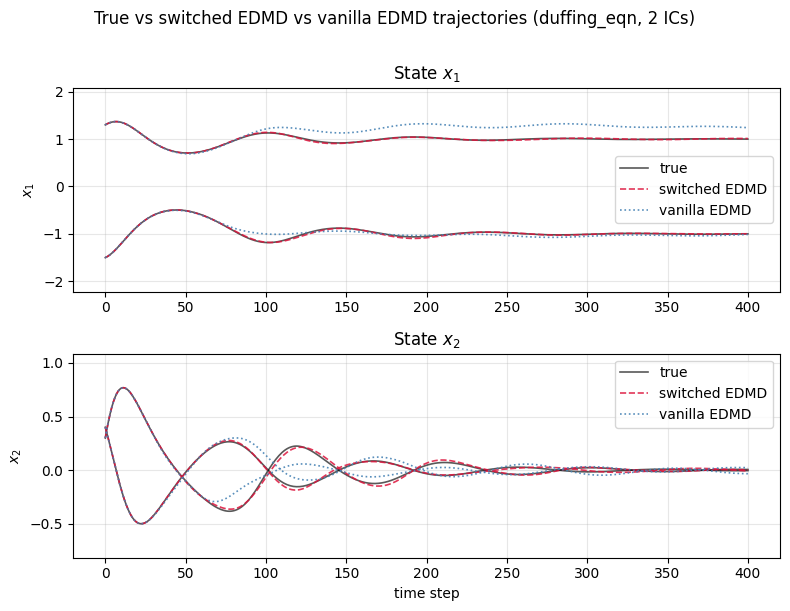

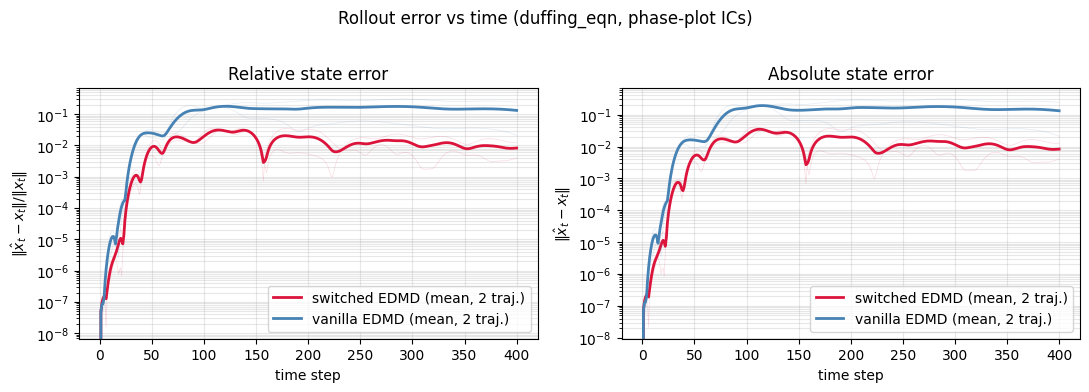

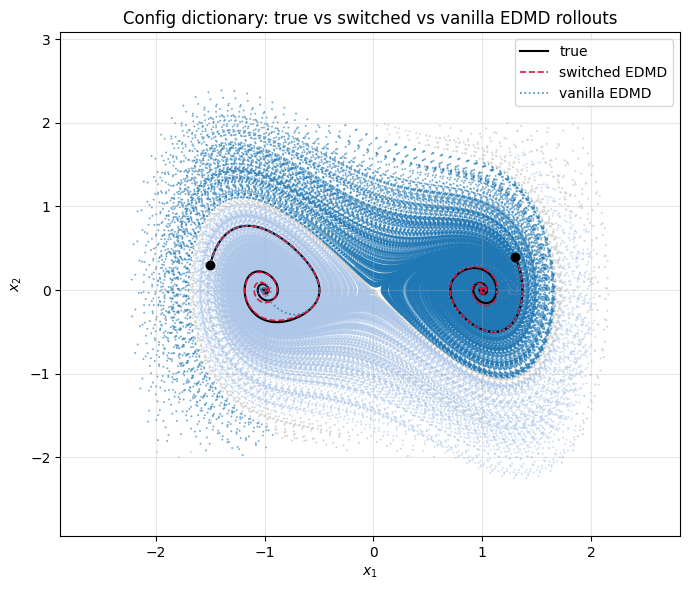

In [17]:
Phi_cfg, switched_cfg, vanilla_cfg = build_edmd_models(EDMD["edmd_gamma"], EDMD["edmd_d_poly"], EDMD["number_centers_edmd"])
print(f"dictionary: {Phi_cfg.s} elements | switched models on "
      f"{sum(switched_cfg['sample_counts'].values())} pairs ({', '.join(f'cell {l}: {c}' for l, c in sorted(switched_cfg['sample_counts'].items()))})"
      f" | vanilla on {vanilla_cfg['n_samples']} pairs")
print("spectral radius of K:", {f"cell {l}": round(spectral_radius(K), 5) for l, K in switched_cfg["K_by_label"].items()},
      "| vanilla:", round(spectral_radius(vanilla_cfg["K"]), 5))
one_sw, one_van = onestep_state_rel_err(Phi_cfg, switched_cfg, vanilla_cfg)
print(f"in-sample one-step state rel. error: switched {one_sw:.3e} | vanilla {one_van:.3e}")

sw_cfg, van_cfg, m_sw, m_van = rollout_ics(Phi_cfg, switched_cfg, vanilla_cfg)
print()
bmlm._print_rollout_summary(m_sw, m_van, mlm_cfg, gated=False)
bmlm._print_rollout_rel_rmse_times(m_sw, m_van)
_ = bmlm.plot_phase_trajectories(sw_cfg, mlm_cfg["system_name"], vanilla_rollouts=van_cfg, show=True)
_ = bmlm.plot_rollout_errors(m_sw["rel_err_curves"], m_sw["abs_err_curves"], rel_vanilla=m_van["rel_err_curves"],
                              abs_vanilla=m_van["abs_err_curves"], system_name=mlm_cfg["system_name"],
                              subtitle="phase-plot ICs", show=True)
phase_portrait(sw_cfg, van_cfg, "Config dictionary: true vs switched vs vanilla EDMD rollouts")

The switched model tracks both initial conditions to its own equilibrium; the vanilla model has to
represent both basins with one linear operator on the same span, so its rollout is pulled toward a
compromise. Note that the *one-step* fit errors of the two models are of the same order — the gap
opens up only under repeated application of $K$, i.e. it is a question of how $K$-invariant the span
of $\Psi$ is on each cell, not of how well one step is fitted. Section 9 varies the dictionary to see
what controls this.

## 9. Effect of the EDMD dictionary (fixed partition)

Everything above the dictionary is now frozen — the partition `inference_final`, the fit data, the
lift-once rollout, the two initial conditions — and only $\Psi$ changes. Three families:

1. **polynomial only** (`number_centers_edmd = 0`), degree $d = 1, \ldots, 6$;
2. **RBF + polynomial** grids: $n_c \in \{10, 30, 100\}$ centers subsampled from `centers_global`,
   precision $\gamma \in \{0.1, 1, 10\}$ (the code uses $e^{-\gamma\|x-c\|^2}$, so larger $\gamma$
   is *narrower*), degree $d \in \{1, 3, 6\}$.

For every dictionary we record the size $s$, the largest spectral radius $\rho(K_\ell)$ over the
local operators and $\rho(K)$ of the vanilla one, the in-sample one-step state error, and the
rollout errors on the two initial conditions (mean RMSE over the horizon, and the relative error at
the `rollout_rel_rmse_times`). The list is sorted by the switched rollout RMSE.

In [18]:
sweep_grid = [(0.0, d, 0) for d in (1, 2, 3, 4, 5, 6)]                         # polynomial only
sweep_grid += [(g, d, c) for c in (10, 30, 100) for g in (0.1, 1.0, 10.0) for d in (1, 3, 6)]

rows, curves = [], {}
t0 = time.time()
for gamma, d_poly, n_centers in sweep_grid:
    Phi, switched, vanilla = build_edmd_models(gamma, d_poly, n_centers)
    _, _, m_sw_i, m_van_i = rollout_ics(Phi, switched, vanilla)   # do not shadow m_sw / m_van of the config run
    one_sw, one_van = onestep_state_rel_err(Phi, switched, vanilla)
    key = (n_centers, gamma if n_centers else np.nan, d_poly)
    curves[key] = (m_sw_i["rel_err_curves"], m_van_i["rel_err_curves"])
    rows.append(dict(centers=key[0], gamma=key[1], d_poly=d_poly, s=Phi.s,
                     rho_sw=max(spectral_radius(K) for K in switched["K_by_label"].values()),
                     rho_van=spectral_radius(vanilla["K"]),
                     onestep_sw=one_sw, onestep_van=one_van,
                     sw_rmse=m_sw_i["mean_rmse"], van_rmse=m_van_i["mean_rmse"],
                     **{f"sw_rel@{t}": m_sw_i["rel_rmse_at_times"][t] for t in m_sw_i["rel_rmse_times"] if t > 0},
                     **{f"van_rel@{t}": m_van_i["rel_rmse_at_times"][t] for t in m_van_i["rel_rmse_times"] if t > 0}))
print(f"{len(rows)} dictionaries fitted and rolled out in {time.time() - t0:.0f}s")

table_dict = pd.DataFrame(rows).sort_values("sw_rmse").reset_index(drop=True)
fmt = {c: "{:.3g}" for c in table_dict.columns if c not in ("centers", "d_poly", "s")}
display(table_dict.style.format(fmt).background_gradient(subset=["sw_rmse", "van_rmse"], cmap="RdYlGn_r"))

33 dictionaries fitted and rolled out in 141s


,centers,gamma,d_poly,s,rho_sw,rho_van,onestep_sw,onestep_van,sw_rmse,van_rmse,sw_rel@50,sw_rel@100,sw_rel@200,sw_rel@300,van_rel@50,van_rel@100,van_rel@200,van_rel@300
0,100,1,6,128,1,1,1.73e-08,1.75e-08,0.0163,0.152,0.00896,0.0198,0.0189,0.0114,0.0248,0.14,0.156,0.172
1,100,1,3,110,1,1,2.05e-08,5.51e-08,0.0194,0.214,0.00384,0.0251,0.0154,0.0236,0.0396,0.19,0.236,0.252
2,100,1,1,103,1,1,4.56e-06,1.57e-05,0.0197,0.169,0.00976,0.0202,0.0238,0.0249,0.043,0.147,0.16,0.198
3,100,10,6,128,1,1,1.73e-08,1.84e-08,0.0253,0.136,0.0207,0.0497,0.0216,0.0139,0.136,0.2,0.136,0.103
4,100,0.1,3,110,1,1,2.1e-08,4.21e-08,0.0313,0.401,0.0326,0.0616,0.0218,0.0167,0.258,0.607,0.428,0.369
5,30,0.1,6,58,1,1,1.73e-08,1.8e-08,0.0323,0.38,0.0395,0.0537,0.0346,0.0187,0.221,0.549,0.425,0.354
6,30,1,6,58,1,1,1.73e-08,1.79e-08,0.0358,0.311,0.0127,0.0478,0.0363,0.0318,0.221,0.302,0.307,0.289
7,100,10,3,110,1,1,9.84e-07,2.38e-06,0.0358,0.197,0.0256,0.0426,0.0516,0.0169,0.0626,0.205,0.265,0.198
8,100,0.1,6,128,1,1,1.73e-08,1.75e-08,0.0374,0.331,0.0489,0.066,0.0208,0.0214,0.0634,0.452,0.384,0.324
9,100,0.1,1,103,1,1,1.15e-06,2.9e-06,0.0498,0.4,0.0573,0.0915,0.039,0.0362,0.31,0.576,0.444,0.372


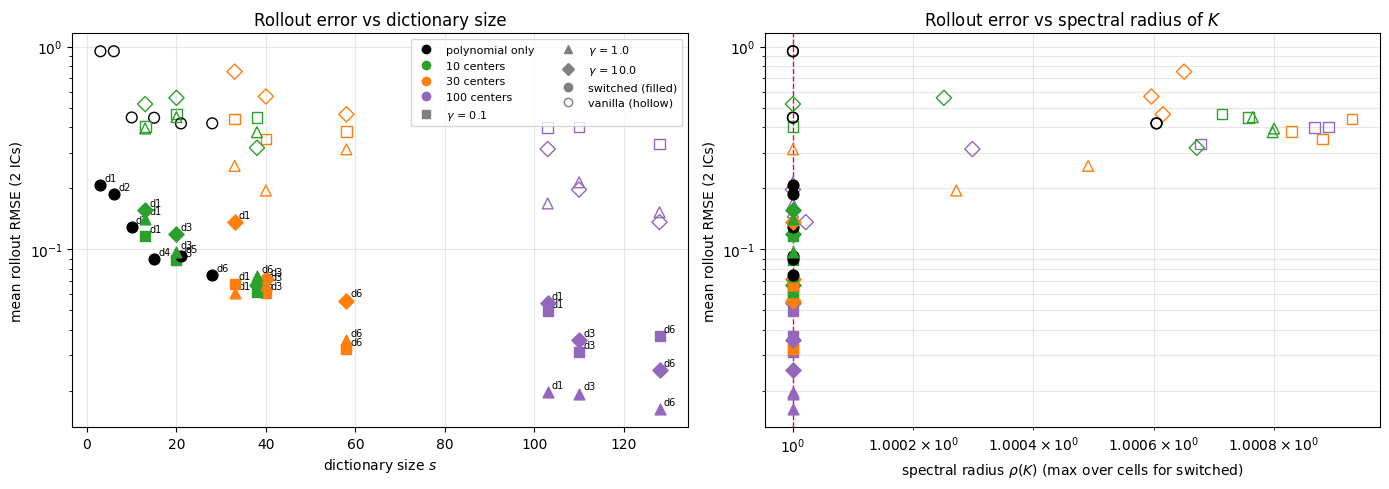

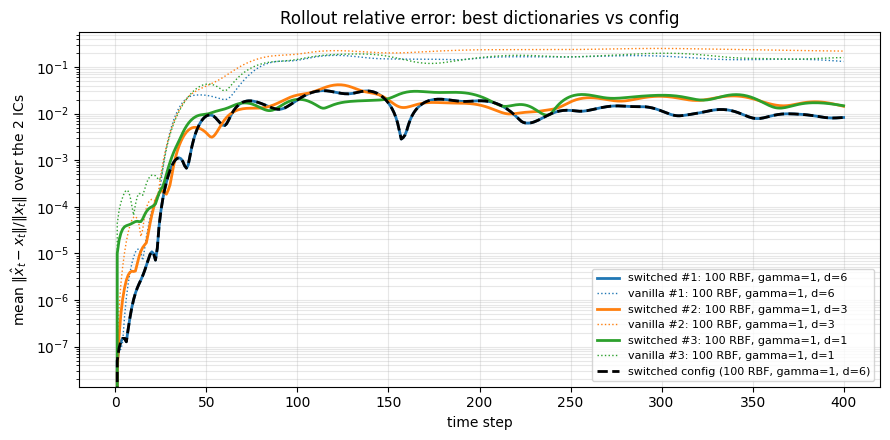

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fam_color = {0: "black", 10: "tab:green", 30: "tab:orange", 100: "tab:purple"}
gam_marker = {np.nan: "o", 0.1: "s", 1.0: "^", 10.0: "D"}
for _, r in table_dict.iterrows():
    mk = gam_marker[r["gamma"] if r["centers"] else np.nan]
    axes[0].scatter(r["s"], r["sw_rmse"], color=fam_color[r["centers"]], marker=mk, s=60, zorder=3)
    axes[0].scatter(r["s"], r["van_rmse"], facecolors="none", edgecolors=fam_color[r["centers"]], marker=mk, s=60, zorder=3)
    axes[0].annotate(f"d{int(r['d_poly'])}", (r["s"], r["sw_rmse"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
    axes[1].scatter(r["rho_sw"], r["sw_rmse"], color=fam_color[r["centers"]], marker=mk, s=60, zorder=3)
    axes[1].scatter(r["rho_van"], r["van_rmse"], facecolors="none", edgecolors=fam_color[r["centers"]], marker=mk, s=60, zorder=3)
from matplotlib.lines import Line2D
handles = [Line2D([], [], color=c, marker="o", ls="", label=f"{k} centers" if k else "polynomial only") for k, c in fam_color.items()]
handles += [Line2D([], [], color="gray", marker=m, ls="", label=rf"$\gamma$ = {g}") for g, m in gam_marker.items() if g == g]
handles += [Line2D([], [], color="gray", marker="o", ls="", label="switched (filled)"),
            Line2D([], [], color="gray", marker="o", ls="", markerfacecolor="none", label="vanilla (hollow)")]
axes[0].set_xlabel("dictionary size $s$"); axes[0].set_ylabel("mean rollout RMSE (2 ICs)"); axes[0].set_yscale("log")
axes[0].set_title("Rollout error vs dictionary size"); axes[0].grid(alpha=0.3); axes[0].legend(handles=handles, fontsize=8, ncol=2)
axes[1].axvline(1.0, color="crimson", ls="--", lw=1)
axes[1].set_xlabel(r"spectral radius $\rho(K)$ (max over cells for switched)"); axes[1].set_ylabel("mean rollout RMSE (2 ICs)")
axes[1].set_yscale("log"); axes[1].set_xscale("log"); axes[1].set_title("Rollout error vs spectral radius of $K$"); axes[1].grid(alpha=0.3, which="both")
plt.tight_layout(); plt.show()

# error curves of the best three switched dictionaries and of the config one
fig, ax = plt.subplots(figsize=(9, 4.5))
t = np.arange(horizon + 1)
for rank in range(3):
    r = table_dict.iloc[rank]
    key = (int(r["centers"]), r["gamma"] if r["centers"] else np.nan, int(r["d_poly"]))
    lab = f"#{rank + 1}: {'poly only' if not key[0] else f'{key[0]} RBF, gamma={key[1]:g}'}, d={key[2]}"
    with np.errstate(all="ignore"):
        ax.plot(t, np.nanmean(curves[key][0], axis=0), lw=2, label=f"switched {lab}")
        ax.plot(t, np.nanmean(curves[key][1], axis=0), lw=1, ls=":", color=ax.lines[-1].get_color(), label=f"vanilla {lab}")
with np.errstate(all="ignore"):
    ax.plot(t, np.nanmean(m_sw["rel_err_curves"], axis=0), lw=2, color="black", ls="--",
            label=f"switched config ({EDMD['number_centers_edmd']} RBF, gamma={EDMD['edmd_gamma']:g}, d={EDMD['edmd_d_poly']})")
ax.set_yscale("log"); ax.set_xlabel("time step"); ax.set_ylabel(r"mean $\|\hat{x}_t - x_t\| / \|x_t\|$ over the 2 ICs")
ax.set_title("Rollout relative error: best dictionaries vs config"); ax.grid(alpha=0.3, which="both"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

best switched dictionary: centers = 100, gamma = 1.0, d_poly = 6  (s = 128)


+---------------------------------+---+------------+-----------+-----------+----------+
| Time step                       | 0 | 50         | 100       | 200       | 300      |
+=================================+===+============+===========+===========+==========+
| Mean rel. error (switched EDMD) | 0 | 0.00895642 | 0.0197904 | 0.0189262 | 0.011444 |
| Mean rel. error (vanilla EDMD)  | 0 | 0.0247835  | 0.140154  | 0.155938  | 0.17231  |
+---------------------------------+---+------------+-----------+-----------+----------+


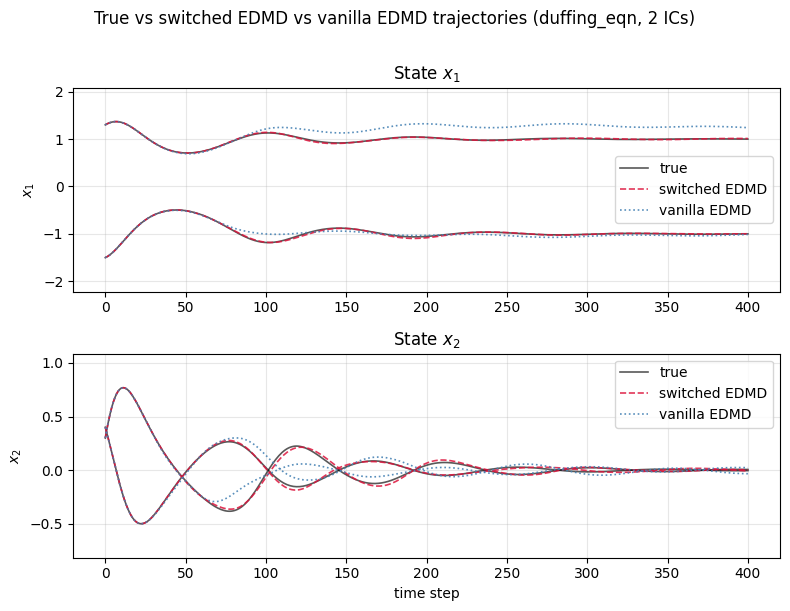

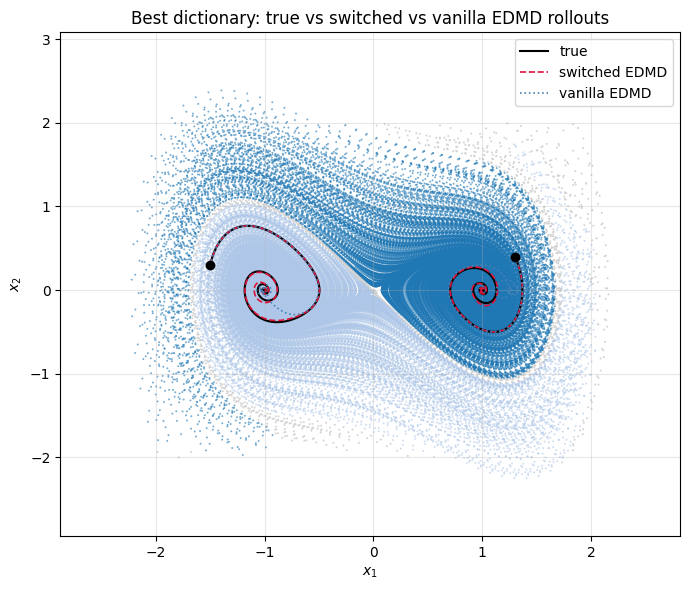

In [20]:
best = table_dict.iloc[0]
best_key = (int(best["centers"]), float(best["gamma"]) if best["centers"] else 0.0, int(best["d_poly"]))
print(f"best switched dictionary: centers = {best_key[0]}, gamma = {best_key[1]}, d_poly = {best_key[2]}  (s = {int(best['s'])})")
Phi_b, switched_b, vanilla_b = build_edmd_models(best_key[1], best_key[2], best_key[0])
sw_b, van_b, m_sw_b, m_van_b = rollout_ics(Phi_b, switched_b, vanilla_b)
bmlm._print_rollout_rel_rmse_times(m_sw_b, m_van_b)
_ = bmlm.plot_phase_trajectories(sw_b, mlm_cfg["system_name"], vanilla_rollouts=van_b, show=True)
phase_portrait(sw_b, van_b, "Best dictionary: true vs switched vs vanilla EDMD rollouts")

### What works best, and why

**Ranking.** The switched model beats the vanilla one for *every* one of the 33 dictionaries, by
4–20× in rollout RMSE; the best vanilla dictionary (100 centers, $\gamma = 10$, $d = 6$: 0.136) is
worse than every switched dictionary that has at least 10 RBF centers. Among the switched models:

| family | best member | mean rollout RMSE | rel. error at $t = 300$ |
|---|---|---|---|
| 100 RBF centers, $\gamma = 1$ | $d = 6$ ($s = 128$) | **0.016** | 0.011 |
| 100 RBF centers, $\gamma = 1$ | $d = 3$ ($s = 110$) | 0.019 | 0.024 |
| 100 RBF centers, $\gamma = 1$ | $d = 1$ ($s = 103$) | 0.020 | 0.025 |
| 30 RBF centers, $\gamma \in \{0.1, 1\}$ | $d = 6$ ($s = 58$) | 0.032–0.036 | 0.019–0.032 |
| 10 RBF centers | $d = 6$ ($s = 38$) | 0.062–0.074 | 0.032–0.054 |
| polynomial only | $d = 6$ ($s = 28$) | 0.075 | 0.042 |
| polynomial only | $d = 1$ ($s = 3$) | 0.207 | 0.066 |
| config ($30$ centers, $\gamma = 0.01$, $d = 6$) | — | 0.070 | 0.052 |

Three things decide the order:

1. **Number of RBF centers matters most.** With $\gamma = 1$, going from 0 to 10, 30, 100 centers
   at fixed $d = 6$ takes the RMSE from 0.075 to 0.074, 0.036, 0.016. Once there are 100 centers,
   the polynomial degree is almost irrelevant ($d = 1, 3, 6$ all give 0.016–0.020) — the RBFs are
   what make the span rich enough to be nearly $K$-invariant along the spiral into the equilibrium.
2. **Bandwidth: $\gamma \approx 1$ is the sweet spot.** In the code $\psi_c(x) = e^{-\gamma\|x-c\|^2}$,
   so $\gamma = 1$ gives bumps of width $\sim 1$, comparable to the basin size ($\sim 2$).
   $\gamma = 10$ (width $\sim 0.3$) is too narrow: with only 30 centers it leaves gaps between the
   bumps and is the worst RBF family (0.056–0.136); it only recovers with 100 centers. $\gamma = 0.1$
   (width $\sim 3$) makes every RBF look like a low-order polynomial on the data, so it adds little
   beyond the polynomial part (30 centers, $\gamma = 0.1$, $d = 6$ at 0.032 is about the same as
   $\gamma = 1$). The config's $\gamma = 0.01$ is even flatter, which is why its 30-center, $d = 6$
   dictionary (0.070) performs like the polynomial-only $d = 6$ dictionary (0.075) — the RBFs are
   effectively wasted.
3. **Polynomial degree has a floor effect.** Polynomial-only improves monotonically from $d = 1$
   (0.21) to $d = 6$ (0.075); the cubic vector field is in the span only from $d = 3$, and higher
   degrees are needed to represent the nonlinear observables that actually evolve linearly (the
   Koopman eigenfunctions). But past $d \approx 3$–$6$ the return diminishes and RBFs are the
   cheaper way to buy capacity.

**Why the one-step fit does not predict the rollout.** Every $d = 6$ dictionary has an in-sample
one-step state error of $1.7$–$2.0 \times 10^{-8}$ — identical to two digits — yet their rollout
RMSEs span $0.016$ to $0.075$. Degree 6 alone already fits one step to the noise floor of the RK4
data; what differs between the dictionaries is how much of $z_t K$ *leaves* the span of $\Psi$. In a
lift-once rollout that leak is never corrected (there is no re-lifting), so it compounds over 400
steps. The rollout error therefore measures the $K$-invariance of $\mathrm{span}\,\Psi$ on the cell,
which is a property of the *dictionary*, not of the least-squares residual.

**Why switching wins regardless of dictionary — the spectral radius.** Every local operator $K_\ell$
has $\rho(K_\ell) = 1$ to machine precision: the constant function is an eigenfunction with
eigenvalue 1, and everything else contracts, which is exactly the spectrum of a system with one
stable equilibrium in the cell. The vanilla operator instead has $\rho(K) = 1.0002$–$1.0008 > 1$ for
most RBF dictionaries: forced to represent two attractors with one linear map on a continuous span,
the least-squares solution acquires a slowly growing direction, and the vanilla rollouts drift
(relative error 0.15–0.5, still growing at $t = 300$) instead of settling. The switched errors
*decrease* with $t$ for every dictionary (the local $K_\ell$ contracts onto the correct equilibrium,
so the transient error is forgotten), which is the qualitative signature of a correct $\omega$-limit
partition. No choice of dictionary fixes this for the vanilla model, because the obstruction is the
partition, not the span.

**Recommendation.** For the paper's Duffing example use `edmd_gamma = 1.0`, `number_centers_edmd =
100`, `edmd_d_poly = 3` (or 6); this is 4× better than the current config on these two initial
conditions at negligible extra cost ($s = 110$–$128$; the fit on 400k pairs takes seconds). If the
dictionary has to stay small, `30` centers with `gamma` in $[0.1, 1]$ and `d_poly = 6` is the best
$s \approx 60$ option. Two caveats: the ranking within the top group (0.016–0.025) rests on only two
initial conditions and should be confirmed with `run_gated_evaluation = true` before it goes into
Table I; and the spectral radii above are for `reclassify_each_step = false` — with reclassification
the lifted state is handed between operators, which this sweep does not exercise.